# Vehicle categories, structure and similarity

V4 adds provisional market/performance categories and category-aware subgroups. Its read-only inspection appears first. Preserved v3 sections below inspect direct specification similarity and earlier blinded reviews; v3 category labels were descriptive rather than discovery inputs. No notebook cell in the new v4 section launches collection or fitting.


In [1]:
from pathlib import Path
import os, sys, json, importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, FileLink
root = Path.cwd()
if not (root / "MODELS").is_dir():
    root = root.parent
sys.path.insert(0, str(root))
from MODELS import vehicle_profiles as research
research = importlib.reload(research)
from MODELS import vehicle_segmentation as segmentation
segmentation = importlib.reload(segmentation)
from MODELS import vehicle_taxonomy as taxonomy
taxonomy = importlib.reload(taxonomy)
from MODELS import vehicle_taxonomy_v2 as taxonomy_v2
taxonomy_v2 = importlib.reload(taxonomy_v2)
from MODELS import vehicle_similarity_v3 as similarity
similarity = importlib.reload(similarity)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False, "axes.spines.right": False, "font.size": 11})

## Provisional vehicle categories (v4)

The v4 CLI prepares profiles, collects scoped evidence, builds categories, fits family-held-out subgroups, validates outputs, and explicitly activates the dashboard bundle. Run commands from the README; this notebook only inspects completed artifacts. Labels overlap and remain provisional. Unknowns and unsupported subdivisions stay explicit. Price-model features are a future experiment.


In [ ]:
from MODELS import vehicle_similarity_v4 as similarity_v4
v4_base = root / "MODEL_OUTPUT/vehicle_similarity_v4"
v4_pin = os.environ.get("VEHICLE_SIMILARITY_V4_RUN_DIR")
v4_candidates = []
for manifest_path in v4_base.glob("*/run/manifest.json"):
    manifest = research.read_json(manifest_path)
    if manifest.get("status") == "completed" and manifest.get("schema_version") == "4.0.0" and not manifest.get("reduced_budget", True):
        v4_candidates.append(manifest_path.parent)
# Also accept a completed run written directly under the v4 output directory.
for manifest_path in v4_base.glob("*/manifest.json"):
    manifest = research.read_json(manifest_path)
    if manifest.get("status") == "completed" and manifest.get("schema_version") == "4.0.0" and not manifest.get("reduced_budget", True) and (manifest_path.parent / "profile_peers.parquet").is_file():
        v4_candidates.append(manifest_path.parent)
v4_run = Path(v4_pin) if v4_pin else (max(v4_candidates, key=lambda p: research.read_json(p / "manifest.json")["completed_at"]) if v4_candidates else None)
if v4_run is None:
    print("No completed full v4 run yet. Use the README commands; the preserved v3 sections follow.")
else:
    v4_receipt = similarity_v4.verified(v4_run, "completed")
    if v4_receipt.get("reduced_budget", True):
        raise ValueError("Select a completed full-budget v4 run")
    print("Saved v4 analysis:", v4_run)
    display(pd.read_csv(v4_run / "category_coverage.csv"))
    display(pd.read_parquet(v4_run / "profile_labels.parquet").head(30))
    display(pd.read_csv(v4_run / "cluster_profiles.csv").head(30))
    display(pd.read_csv(v4_run / "benchmark_diagnostics.csv"))


In [2]:
similarity_base = root / "MODEL_OUTPUT/vehicle_similarity_v3"
saved_similarity = os.environ.get("VEHICLE_SIMILARITY_V3_RUN_DIR")
if saved_similarity:
    similarity_run = Path(saved_similarity)
else:
    completed = [p.parent for p in similarity_base.glob("*/manifest.json")
                 if research.read_json(p).get("status") == "completed"
                 and research.read_json(p).get("schema_version") == "3.0.0"
                 and not research.read_json(p).get("reduced_budget", True)
                 and (p.parent / "variant_profiles.parquet").is_file()]
    if not completed:
        raise FileNotFoundError("Run the v3 analyze CLI with a fresh output directory before reading this section.")
    similarity_run = max(completed, key=lambda p: research.read_json(p / "manifest.json")["completed_at"])
similarity_receipt = taxonomy.verify_artifacts(similarity_run)
similarity_profiles = pd.read_parquet(similarity_run / "variant_profiles.parquet")
similarity_status = pd.read_parquet(similarity_run / "query_status.parquet")
similarity_peers = pd.read_parquet(similarity_run / "profile_peers.parquet")
similarity_queries = pd.read_csv(similarity_run / "evaluation_queries.csv")
similarity_experiments = pd.read_csv(similarity_run / "cluster_experiments.csv")
print("Saved v3 analysis:", similarity_run)
# Completed reviews are separate immutable outputs, bound to this analysis manifest.
similarity_evaluation = research.read_json(similarity_run / "evaluation.json")
similarity_evaluation_dir = None
reviewed_candidates = [p.parent for p in similarity_base.glob("*/manifest.json")
                       if research.read_json(p).get("status") == "completed"
                       and research.read_json(p).get("run_manifest_sha256") == research.file_hash(similarity_run / "manifest.json")
                       and (p.parent / "scored_reviews.csv").is_file()]
if reviewed_candidates:
    similarity_evaluation_dir = max(reviewed_candidates, key=lambda p: (p / "manifest.json").stat().st_mtime)
    taxonomy.verify_artifacts(similarity_evaluation_dir)
    similarity_evaluation = research.read_json(similarity_evaluation_dir / "evaluation.json")
display(pd.Series(similarity_evaluation).to_frame("current evaluation"))


Saved v3 analysis: E:\DataScience_Capstone_Cars\MODEL_OUTPUT\vehicle_similarity_v3\20261024-full


,current evaluation
schema_version,3.0.0
status,partially_reviewed
cards,100
fully_graded_pairs,98
preference_cards,99
complete_cards,97
excluded_usefulness_cards,"[C012, C035]"
missing_judgments,"[{'card_id': 'C004', 'field': 'winner'}, {'car..."
allow_incomplete,True
reviewers,[daniel rodriguez]


## Selected-run summary

Stable clusters alone do not establish useful alternatives. Adoption requires the frozen independent-review rule.

In [3]:
confirmed = similarity_experiments[similarity_experiments.get("median_ari", pd.Series(index=similarity_experiments.index, dtype=float)).notna()]
accepted = similarity_experiments[similarity_experiments.status.eq("accepted_partition")]
query_status = similarity_status[similarity_status.query_profile_id.isin(similarity_queries.profile_id)]
query_identity_support = similarity_queries.merge(similarity_profiles[["profile_id", "family_resolved"]], on="profile_id", validate="1:1")
benchmark_peer_rows = similarity_peers[similarity_peers.query_profile_id.isin(similarity_queries.profile_id)]
benchmark_sets = {(query, approach): frozenset(group.peer_profile_id)
                  for (query, approach), group in benchmark_peer_rows.groupby(["query_profile_id", "approach"])}
changed_candidate_sets = sum(benchmark_sets.get((query, "direct_specs"), frozenset()) != benchmark_sets.get((query, "cluster_aware"), frozenset())
                             for query in similarity_queries.profile_id)
summary = pd.Series({
    "Retained listing VINs": int(similarity_profiles.vin_count.sum()),
    "Profiles": len(similarity_profiles),
    "Out-of-fold eligible profiles": int(similarity_profiles.eligible.sum()),
    "Benchmark queries / distinct family blocks": f"{len(similarity_queries)} / {similarity_queries.family_block.nunique()}",
    "Benchmark sourced family mappings": int(query_identity_support.family_resolved.sum()),
    "Benchmark decoded-name fallback blocks": int((~query_identity_support.family_resolved).sum()),
    "Accepted body-family partitions across folds": int(accepted.view.ne("global").sum()),
    "Queries with changed candidate sets": changed_candidate_sets,
    "Human usefulness evaluation": similarity_evaluation["status"],
    "Semantic label accuracy": "not measured",
})
display(summary.to_frame("value"))
display(similarity.diagnostics(query_status, similarity_peers[similarity_peers.query_profile_id.isin(similarity_queries.profile_id)]).round(3))

,value
Retained listing VINs,2792999
Profiles,21285
Out-of-fold eligible profiles,10918
Benchmark queries / distinct family blocks,100 / 100
Benchmark sourced family mappings,11
Benchmark decoded-name fallback blocks,89
Accepted body-family partitions across folds,9
Queries with changed candidate sets,7
Human usefulness evaluation,partially_reviewed
Semantic label accuracy,not measured


,approach,queries,families,queries_with_peers,complete_list_share,empty_list_share,mean_slate_size,mean_returned_distance,distance_is_usefulness
0,cluster_aware,100,100,100,1.0,0.0,5.0,0.039,False
1,direct_specs,100,100,100,1.0,0.0,5.0,0.039,False


## Evidence and retrieval coverage

Each profile uses its held-out family fold. Empty/ineligible queries remain in coverage. Overlapping family counts are not additive.

,profiles,listings,eligible,with_peers
powertrain,,,,
battery_electric,151,15781,1,0
conflicting,4,8,0,0
hybrid,621,72950,320,317
plug_in_hybrid,283,17931,155,146
unknown,20226,2686329,10442,10442


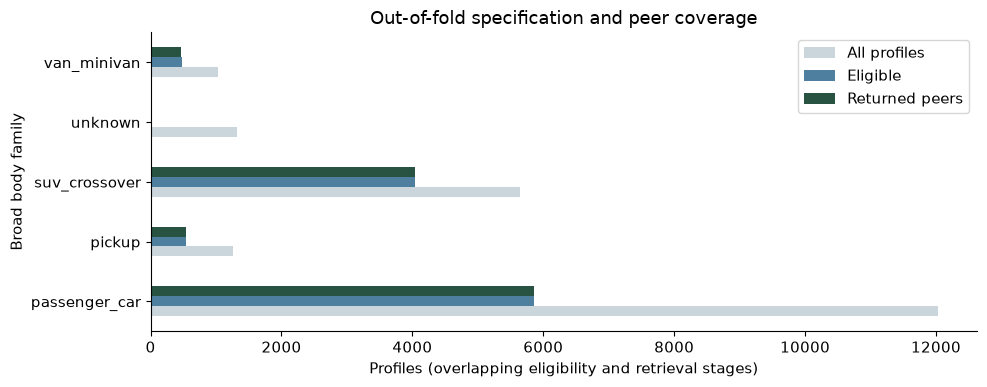

,fold,paired_training_vins,median_ratio,verified
0,0,1077682,1.0,True
1,1,1171733,1.0,True
2,2,1068250,1.0,True
3,3,1164715,1.0,True
4,4,1086616,1.0,True


In [4]:
direct_status = similarity_status[similarity_status.approach.eq("direct_specs")]
evidence_coverage = similarity_profiles.merge(direct_status[["query_profile_id", "slate_size"]], left_on="profile_id", right_on="query_profile_id", validate="1:1")
evidence_coverage["has_peers"] = evidence_coverage.slate_size.gt(0)
body_coverage = evidence_coverage.groupby("body_family").agg(profiles=("profile_id", "size"), eligible=("eligible", "sum"), with_peers=("has_peers", "sum"))
display(evidence_coverage.groupby("powertrain").agg(profiles=("profile_id", "size"), listings=("vin_count", "sum"), eligible=("eligible", "sum"), with_peers=("has_peers", "sum")))
ax = body_coverage.plot.barh(color=["#cbd5dc", "#4f7f9e", "#285342"], figsize=(10, 4))
ax.set(xlabel="Profiles (overlapping eligibility and retrieval stages)", ylabel="Broad body family", title="Out-of-fold specification and peer coverage")
ax.legend(["All profiles", "Eligible", "Returned peers"])
plt.tight_layout()
plt.show()
display(pd.read_csv(similarity_run / "numeric_scale_audit.csv"))


## Finer structure

Primary discovery uses body families; global clustering is a baseline. Thirty-refit confirmation checks stability and family support. Silhouettes from different geometries cannot rank methods. ARI = -1 marks insufficient common anchors (<10 profiles or <80% shared coverage).

,fold,view,method,k,status,median_ari,ari_q10,balanced_min_ari,minimum_cluster_families,silhouette
0,0,global,kmeans,2,accepted_partition,0.952,0.814,0.948,206,0.299
7,0,global,gower,2,no_supported_subdivision,NaN,NaN,NaN,179,0.258
14,0,global,hierarchical,2,no_supported_subdivision,NaN,NaN,NaN,1,-1.000
21,0,passenger_car,kmeans,2,no_supported_subdivision,0.826,0.596,0.625,72,0.320
28,0,passenger_car,gower,2,no_supported_subdivision,0.724,0.006,0.003,118,0.370
...,...,...,...,...,...,...,...,...,...,...
490,4,suv_crossover,gower,2,accepted_partition,0.915,0.639,0.915,66,0.397
497,4,suv_crossover,hierarchical,2,no_supported_subdivision,NaN,NaN,NaN,1,-1.000
504,4,van_minivan,kmeans,2,no_supported_subdivision,NaN,NaN,NaN,7,-1.000
511,4,van_minivan,gower,2,no_supported_subdivision,1.000,0.000,0.000,8,0.795


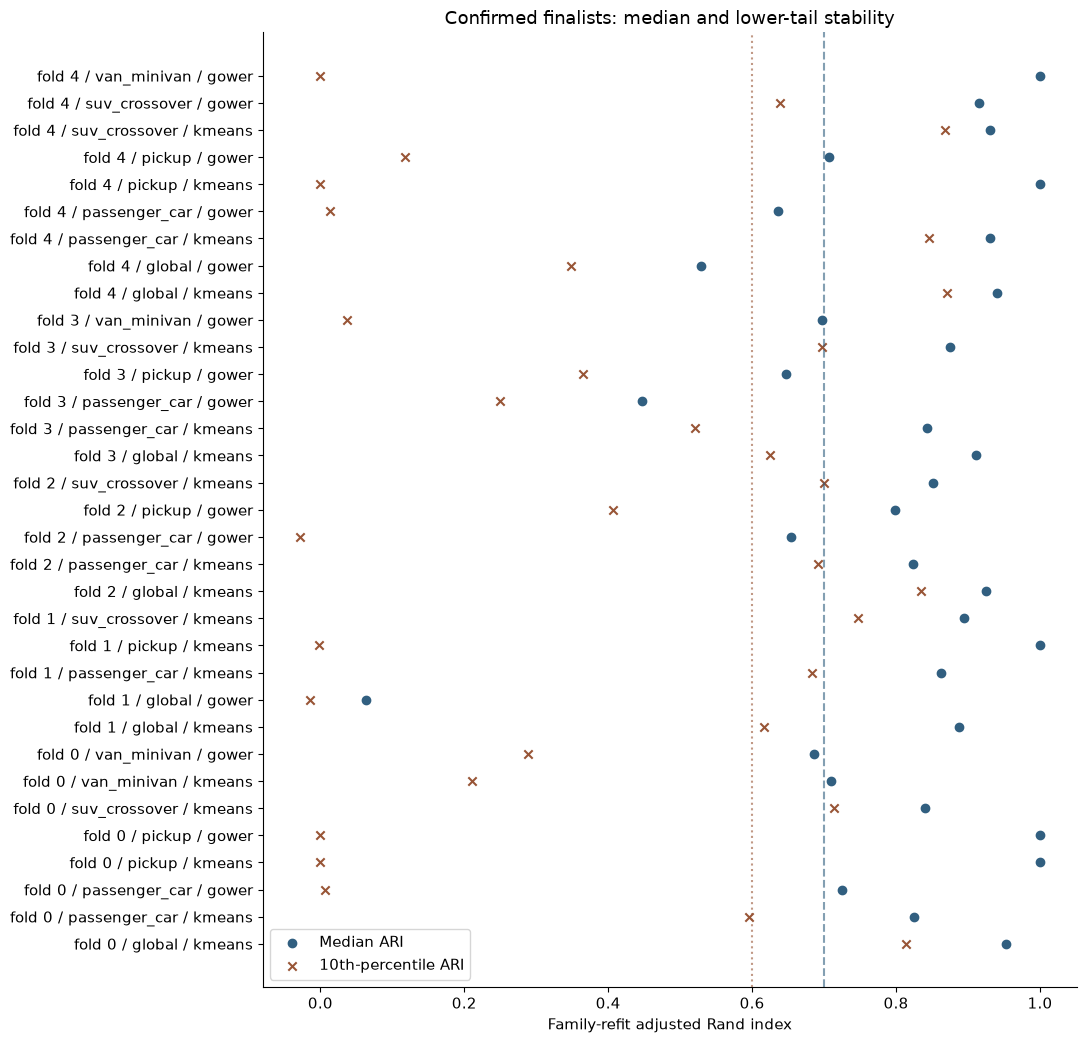

,fold,view,method,k,sensitivity,seed,status,ari
25,0,pickup,kmeans,3,without_transmission,42.0,evaluated,-1.000
32,0,pickup,gower,2,without_transmission,42.0,evaluated,-1.000
114,2,pickup,gower,3,without_transmission,42.0,evaluated,-1.000
149,3,pickup,gower,2,without_transmission,42.0,evaluated,-1.000
78,1,pickup,kmeans,3,equal_family,44.0,evaluated,-0.046
76,1,pickup,kmeans,3,equal_family,42.0,evaluated,-0.046
77,1,pickup,kmeans,3,equal_family,43.0,evaluated,-0.046
12,0,passenger_car,kmeans,2,complete_case,42.0,evaluated,-0.041
196,4,pickup,kmeans,3,equal_family,44.0,evaluated,-0.036
24,0,pickup,kmeans,3,equal_family,44.0,evaluated,-0.030


,fold,view,method,k,sensitivity,seed,status,ari
0,0,global,kmeans,2,equal_family,42.0,evaluated,0.948
1,0,global,kmeans,2,equal_family,43.0,evaluated,0.948
2,0,global,kmeans,2,equal_family,44.0,evaluated,0.948
3,0,global,kmeans,2,without_transmission,42.0,evaluated,0.983
4,0,global,kmeans,2,minmax_scaling,42.0,evaluated,0.972
5,0,global,kmeans,2,complete_case,42.0,evaluated,0.960
6,0,global,kmeans,2,missingness_only,NaN,evaluated,0.150
7,0,passenger_car,kmeans,2,equal_family,42.0,evaluated,0.625
8,0,passenger_car,kmeans,2,equal_family,43.0,evaluated,0.625
9,0,passenger_car,kmeans,2,equal_family,44.0,evaluated,0.625


In [5]:
columns = [c for c in ["fold", "view", "method", "k", "status", "median_ari", "ari_q10", "balanced_min_ari", "minimum_cluster_families", "silhouette"] if c in similarity_experiments]
display(similarity_experiments[similarity_experiments.status.ne("screened_out")][columns].round(3))
if len(confirmed):
    chart = confirmed.copy()
    chart["fit"] = "fold " + chart.fold.astype(str) + " / " + chart.view + " / " + chart.method
    fig, ax = plt.subplots(figsize=(11, max(4, len(chart) * .32)))
    positions = np.arange(len(chart))
    ax.scatter(chart.median_ari, positions, label="Median ARI", color="#315f80")
    ax.scatter(chart.ari_q10, positions, label="10th-percentile ARI", marker="x", color="#985536")
    ax.axvline(.70, linestyle="--", color="#315f80", alpha=.6)
    ax.axvline(.60, linestyle=":", color="#985536", alpha=.6)
    ax.set_yticks(positions, chart.fit)
    ax.set(xlabel="Family-refit adjusted Rand index", title="Confirmed finalists: median and lower-tail stability")
    ax.legend(loc="best")
    fig.tight_layout()
    plt.show()
else:
    display(Markdown("No candidate reached confirmation under the screening rules."))
sensitivity_path = similarity_run / "cluster_sensitivities.csv"
try:
    sensitivity_table = pd.read_csv(sensitivity_path)
except pd.errors.EmptyDataError:
    sensitivity_table = pd.DataFrame()
if len(sensitivity_table):
    evaluated_sensitivities = sensitivity_table[sensitivity_table.status.eq("evaluated")].copy()
    caution = ((evaluated_sensitivities.sensitivity.eq("missingness_only") & evaluated_sensitivities.ari.ge(.70))
               | (~evaluated_sensitivities.sensitivity.eq("missingness_only") & evaluated_sensitivities.ari.lt(.70)))
    sensitivity_cautions = evaluated_sensitivities[caution].sort_values("ari")
    display(sensitivity_cautions.head(30).round(3))
    display(sensitivity_table.head(20).round(3))


## Direct peers and cluster challenger

Both use identical compatible candidates. Supported cluster mismatch adds 0.10; unknown assignments use direct distance. Empty queries stay in coverage denominators.

,approach,queries,families,queries_with_peers,complete_list_share,empty_list_share,mean_slate_size,mean_returned_distance,distance_is_usefulness
0,cluster_aware,100,100,100,1.0,0.0,5.0,0.039,False
1,direct_specs,100,100,100,1.0,0.0,5.0,0.039,False


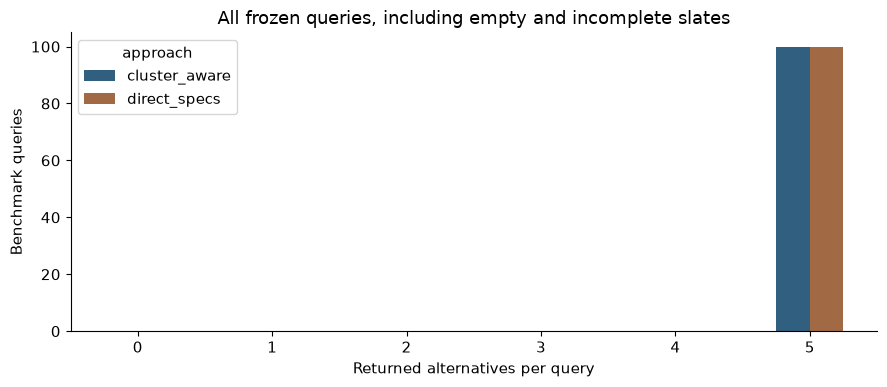

,ModelYear,Make,Model,Trim,profile_id,powertrain,observed_fuels,electrification_evidence,eligible
8116,2009,ROLLS-ROYCE,PHANTOM,DROPHEAD COUPE,1e8e51ec8116eb32ed46781e,unknown,GASOLINE,,True


,query_profile_id,approach,rank,ModelYear,Make,Model,Trim,body_style,powertrain,distance,cluster_penalty,shared_size,shared_powertrain
0,1e8e51ec8116eb32ed46781e,direct_specs,1,2008,BMW,750I,750I/ALPINA B7,sedan,unknown,0.055058,0.0,5,2
1,1e8e51ec8116eb32ed46781e,direct_specs,2,2013,BMW,"750I, ALPINA B7",750I/ALPINA B7,sedan,unknown,0.062596,0.0,5,3
2,1e8e51ec8116eb32ed46781e,direct_specs,3,2013,AUDI,A6,QUATTRO PREMIUM PLUS,sedan,unknown,0.063893,0.0,5,2
3,1e8e51ec8116eb32ed46781e,direct_specs,4,2013,JAGUAR,XF,XF,sedan,unknown,0.065855,0.0,5,2
4,1e8e51ec8116eb32ed46781e,direct_specs,5,2014,BMW,550I,XDRIVE,sedan,unknown,0.066180,0.0,5,3
5,1e8e51ec8116eb32ed46781e,cluster_aware,1,2008,BMW,750I,750I/ALPINA B7,sedan,unknown,0.055058,0.0,5,2
6,1e8e51ec8116eb32ed46781e,cluster_aware,2,2013,BMW,"750I, ALPINA B7",750I/ALPINA B7,sedan,unknown,0.062596,0.0,5,3
7,1e8e51ec8116eb32ed46781e,cluster_aware,3,2013,AUDI,A6,QUATTRO PREMIUM PLUS,sedan,unknown,0.063893,0.0,5,2
8,1e8e51ec8116eb32ed46781e,cluster_aware,4,2013,JAGUAR,XF,XF,sedan,unknown,0.065855,0.0,5,2
9,1e8e51ec8116eb32ed46781e,cluster_aware,5,2014,BMW,550I,XDRIVE,sedan,unknown,0.066180,0.0,5,3


In [6]:
benchmark_diagnostics = pd.read_csv(similarity_run / "benchmark_diagnostics.csv")
display(benchmark_diagnostics.round(3))
slate_counts = pd.crosstab(query_status.slate_size, query_status.approach).reindex(range(6), fill_value=0)
ax = slate_counts.plot.bar(color=["#315f80", "#a16a44"], figsize=(9, 4))
ax.set(xlabel="Returned alternatives per query", ylabel="Benchmark queries", title="All frozen queries, including empty and incomplete slates")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()
selected_identity = tuple(similarity_queries.iloc[0][research.COHORT])
selected_v3, evidence_v3, peers_v3 = similarity.lookup_profiles(similarity_run, *selected_identity)
display(selected_v3[[*research.COHORT, "profile_id", "powertrain", "observed_fuels", "electrification_evidence", "eligible"]])
display(peers_v3[["query_profile_id", "approach", "rank", *research.COHORT, "body_style", "powertrain", "distance", "cluster_penalty", "shared_size", "shared_powertrain"]].head(20))


## Independent review

Grade blinded alternatives 0/1/2 and choose A/B/tie/neither; identical alternatives require identical grades. Keep the blind key separate. Run `vehicle_similarity_v3 evaluate-review` on the exported ratings.

`--allow-incomplete` excludes ungraded query pairs and missing preferences separately, retains all queries in coverage, and cannot adopt clusters.

E:\DataScience_Capstone_Cars\MODEL_OUTPUT\vehicle_similarity_v3\20261024-review\review_cards.html

Ratings template: E:\DataScience_Capstone_Cars\MODEL_OUTPUT\vehicle_similarity_v3\20261024-review\ratings_template.csv
Current retrieval decision: direct_specs
Human review status: partially_reviewed


,approach,useful_at_5,strong_at_5,preferred
0,cluster_aware,0.996,0.708,0.52
1,direct_specs,0.994,0.704,0.48


,review denominator
cards,100
fully_graded_pairs,98
preference_cards,99
complete_cards,97
excluded_usefulness_cards,"[C012, C035]"


,query pairs
cluster minus direct useful@5,
0.0,97
0.2,1


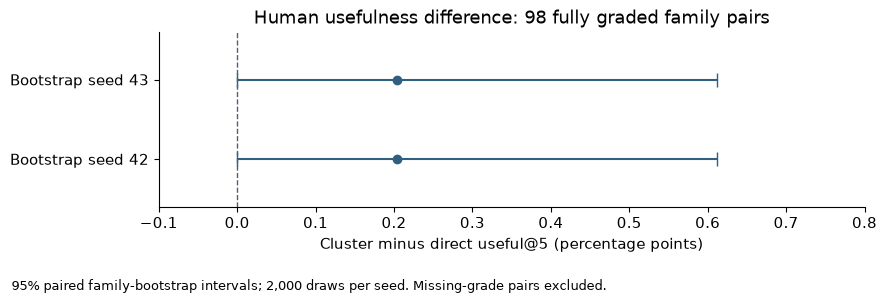

,card_id,approach,useful_at_5,strong_at_5,preferred,fully_graded_pair
10,C006,direct_specs,1.0,0.4,0.0,True
11,C006,cluster_aware,1.0,0.6,1.0,True
68,C035,cluster_aware,NaN,NaN,0.5,False
69,C035,direct_specs,NaN,NaN,0.5,False
74,C038,cluster_aware,1.0,0.4,1.0,True
75,C038,direct_specs,1.0,0.2,0.0,True
88,C045,cluster_aware,1.0,0.6,0.5,True
89,C045,direct_specs,1.0,0.8,0.5,True
128,C065,direct_specs,0.6,0.0,0.0,True
129,C065,cluster_aware,0.8,0.2,1.0,True


In [7]:
review_directories = [p.parent for p in similarity_base.glob("*/manifest.json")
                      if research.read_json(p).get("status") == "exported"
                      and research.read_json(p).get("run_manifest_sha256") == research.file_hash(similarity_run / "manifest.json")]
for review_directory in sorted(review_directories):
    display(FileLink(os.path.relpath(review_directory / "review_cards.html", Path.cwd())))
    print("Ratings template:", review_directory / "ratings_template.csv")
if not review_directories:
    print("Create review cards with the v3 export-review CLI stage.")
print("Current retrieval decision:", similarity_evaluation["selected_approach"])
print("Human review status:", similarity_evaluation["status"])
if similarity_evaluation_dir:
    display(pd.read_csv(similarity_evaluation_dir / "review_summary.csv").round(3))
    display(pd.Series({key: similarity_evaluation.get(key) for key in
                       ["cards", "fully_graded_pairs", "preference_cards", "complete_cards", "excluded_usefulness_cards"]}).to_frame("review denominator"))
    reviewed_scores = pd.read_csv(similarity_evaluation_dir / "scored_reviews.csv")
    useful_pairs = reviewed_scores.pivot(index="card_id", columns="approach", values="useful_at_5").dropna()
    useful_changes = useful_pairs.cluster_aware - useful_pairs.direct_specs
    display(useful_changes.round(6).value_counts().rename_axis("cluster minus direct useful@5").to_frame("query pairs"))
    estimate_pp = similarity_evaluation["mean_useful_at_5_change"] * 100
    intervals_pp = np.array(similarity_evaluation["paired_95_intervals_seeds_42_43"]) * 100
    fig, ax = plt.subplots(figsize=(9, 3))
    for position, (lower, upper) in enumerate(intervals_pp):
        ax.errorbar(estimate_pp, position, xerr=[[estimate_pp-lower], [upper-estimate_pp]],
                    fmt="o", color="#315f80", capsize=5)
    ax.axvline(0, color="#52606b", linestyle="--", linewidth=1)
    ax.set(yticks=[0, 1], yticklabels=["Bootstrap seed 42", "Bootstrap seed 43"], ylim=(-.6, 1.6),
           xlabel="Cluster minus direct useful@5 (percentage points)",
           title=f"Human usefulness difference: {len(useful_pairs)} fully graded family pairs")
    ax.set_xlim(min(-.1, intervals_pp.min()-.1), max(.8, intervals_pp.max()+.1))
    fig.text(.02, .01, "95% paired family-bootstrap intervals; 2,000 draws per seed. Missing-grade pairs excluded.", fontsize=9)
    fig.tight_layout(rect=(0, .08, 1, 1))
    plt.show()
    changed_query_ids = [query for query in similarity_queries.profile_id
                         if benchmark_sets.get((query, "direct_specs"), frozenset()) != benchmark_sets.get((query, "cluster_aware"), frozenset())]
    changed_scores = reviewed_scores[reviewed_scores.query_profile_id.isin(changed_query_ids)]
    display(changed_scores[["card_id", "approach", "useful_at_5", "strong_at_5", "preferred", "fully_graded_pair"]].round(3))


## Decision

Retain direct retrieval: the incomplete review does not pass the positive-lower-bound rule. Near-ceiling scores, few changed slates, one reviewer, and unresolved aliases limit generalization.

Audit rejected/changed alternatives and improve identity/specification evidence. Evaluate revised buyer-fit rules on fresh blinded cases; existing judgments become development feedback.

# Preserved v2 baseline

Historical outputs retain their original policies and denominators.

## Vehicle identities and variants

Decoded cohorts and observed body/powertrain variants remain distinct. Automated checks do not measure semantic accuracy or buyer usefulness.

In [8]:
from pathlib import Path
import os, sys, json, importlib
import pandas as pd
from IPython.display import display, Markdown
root = Path.cwd()
if not (root / "MODELS").is_dir():
    root = root.parent
sys.path.insert(0, str(root))
# Refresh dependencies in order when reusing a kernel after pipeline updates.
from MODELS import vehicle_profiles as research
research = importlib.reload(research)
from MODELS import vehicle_segmentation as segmentation
segmentation = importlib.reload(segmentation)
from MODELS import vehicle_taxonomy as taxonomy
taxonomy = importlib.reload(taxonomy)

from MODELS import vehicle_taxonomy_v2 as taxonomy_v2
taxonomy_v2 = importlib.reload(taxonomy_v2)


In [9]:
base = root / "MODEL_OUTPUT/vehicle_taxonomy_v2"
if os.environ.get("VEHICLE_TAXONOMY_V2_REFIT") == "1":
    prepared = Path(os.environ["VEHICLE_TAXONOMY_V2_PREPARED"])
    taxonomy_run = base / research.datetime.now(research.timezone.utc).strftime("%Y%m%dT%H%M%S%fZ-analysis")
    taxonomy_v2.analyze(prepared, taxonomy_run)
elif os.environ.get("VEHICLE_TAXONOMY_V2_RUN_DIR"):
    taxonomy_run = Path(os.environ["VEHICLE_TAXONOMY_V2_RUN_DIR"])
else:
    candidates = [p.parent for p in base.glob("*/manifest.json") if research.read_json(p).get("status") == "completed" and not research.read_json(p).get("reduced_budget", True) and research.read_json(p).get("schema_version") == "2.0.0"]
    if not candidates:
        raise FileNotFoundError("No completed full-budget v2 analysis. Run the prepare and analyze CLI stages first.")
    taxonomy_run = max(candidates, key=lambda path: research.read_json(path / "manifest.json")["completed_at"])
receipt = taxonomy.verify_artifacts(taxonomy_run)
profiles = pd.read_parquet(taxonomy_run / "variant_profiles.parquet")
parents = pd.read_parquet(taxonomy_run / "cohorts.parquet")
labels = pd.read_parquet(taxonomy_run / "profile_labels.parquet")
print("Saved v2 run:", taxonomy_run)
display(pd.Series({k: receipt.get(k) for k in ["status", "schema_version", "reduced_budget", "human_review", "semantic_accuracy"]}).to_frame("value"))

Saved v2 run: E:\DataScience_Capstone_Cars\MODEL_OUTPUT\vehicle_taxonomy_v2\20261023T173930-analysis


,value
status,completed
schema_version,2.0.0
reduced_budget,False
human_review,not_performed_by_design
semantic_accuracy,not_measured


## Population and support

Incomplete identities remain audit-only; unknown-powertrain peers are exploratory.

,stage,listings,profiles,cohorts,family_blocks
0,all_retained,2792999,21285,14258,1232
1,complete_identity,2278902,16070,14258,735
2,specification_eligible,2158235,10956,10116,544
3,known_powertrain_eligible,68003,476,465,80
4,semantic_label,132431,1803,1454,34


profiles  listings
identity_complete powertrain       eligible                    
False             battery_electric False           58      3739
                  conflicting      False            3         7
                  hybrid           False          119     13581
                  plug_in_hybrid   False           40      2374
                  unknown          False         4995    494396
True              battery_electric False           92     11886
                                   True             1       156
                  conflicting      False            1         1
                  hybrid           False          182      3622
                                   True           320     55747
                  plug_in_hybrid   False           88      3457
                                   True           155     12100
                  unknown          False         4751    101701
                                   True         10480   2090232

,field,block,development_coverage,reason
0,seating,size,0.941788,selected
1,wheelbase,size,0.951876,selected
2,length,size,0.951981,redundant_with_wheelbase
3,height,size,0.952086,selected
4,front_legroom,size,0.932647,selected
5,back_legroom,size,0.879794,selected
6,horsepower,powertrain,0.914364,selected
7,torque_nm,powertrain,0.855627,redundant_with_horsepower
8,fuel_type,powertrain,0.919618,selected
9,transmission,powertrain,0.798256,selected


,source scale checks
horsepower,"{'paired_development_vins': 1077682, 'median_s..."


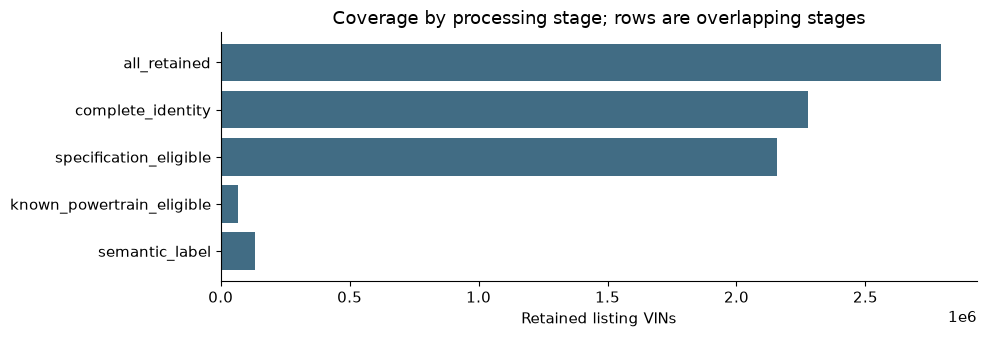

In [10]:
display(pd.read_csv(taxonomy_run / "population_funnel.csv"))
display(profiles.groupby(["identity_complete", "powertrain", "eligible"]).agg(profiles=("profile_id", "size"), listings=("vin_count", "sum")))
display(pd.read_csv(taxonomy_run / "feature_support.csv"))
display(pd.Series(research.read_json(taxonomy_run / "numeric_scale_audit.json")).to_frame("source scale checks"))
import matplotlib.pyplot as plt
funnel = pd.read_csv(taxonomy_run / "population_funnel.csv")
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.barh(funnel.stage, funnel.listings, color="#416c84")
ax.set_xlabel("Retained listing VINs")
ax.set_title("Coverage by processing stage; rows are overlapping stages")
ax.invert_yaxis()
fig.tight_layout()
plt.show()

## Identity and classification coverage

Source scope controls labels without renaming decoded models. Family blocks connect accepted aliases across years. Missing categories are unknown, not negative labels.

identities  listings
dimension             reason                                          
market_positioning    ambiguous_scope                     81    994686
                      missing_reference                   24    214667
                      source_supported                    26    113610
                      unavailable_classification          57    555778
                      unmatched_identity                 554    400161
performance_character ambiguous_scope                     76   1027143
                      missing_reference                   38    243554
                      source_supported                    11     23509
                      unavailable_classification          62    584029
                      unmatched_identity                 555    400667
size_segment          ambiguous_scope                     77    920867
                      missing_reference                   36    233492
                      source_supported                    42    498621
                      unavailable_classification          31    225162
                      unmatched_identity                 556    400760

,dimension,label,profiles
0,body_style,convertible,1156
1,body_style,coupe,1422
2,body_style,hatchback,734
3,body_style,minivan,460
4,body_style,pickup,773
5,body_style,sedan,4889
6,body_style,suv_crossover,4869
7,body_style,van,258
8,body_style,wagon,656
9,market_positioning,economy,4


,mapping_id,assigned_profiles,matching_profiles,zero_match_reason
0,mx5:0,35,35,NaN
1,911:0,168,168,NaN
2,corvette:0,190,190,NaN
3,aventador:0,16,16,NaN
4,aventador-sports:0,16,16,NaN
...,...,...,...,...
82,batch001-pontiac-g6:0,30,31,NaN
83,batch001-lexus-hs:0,3,3,NaN
84,batch001-lamborghini-aventador:0,16,16,NaN
85,honda-fit-2020:0,4,4,NaN


,ModelYear,Make,Model,Trim,body_style,market_family,family_source
2421,2000,BMW,X5,4.4I,suv_crossover,X5,identity-x5
2813,2001,BMW,X5,3.0I,suv_crossover,X5,identity-x5
2814,2001,BMW,X5,4.4I,suv_crossover,X5,identity-x5
3254,2002,BMW,X5,3.0I,suv_crossover,X5,identity-x5
3255,2002,BMW,X5,4.4I,suv_crossover,X5,identity-x5
3256,2002,BMW,X5,4.6IS,suv_crossover,X5,identity-x5
3761,2003,BMW,X5,3.0I,suv_crossover,X5,identity-x5
3762,2003,BMW,X5,4.4I,suv_crossover,X5,identity-x5
4288,2004,BMW,X5,3.0I,suv_crossover,X5,identity-x5
4289,2004,BMW,X5,4.4I,suv_crossover,X5,identity-x5


ambiguous_scope               82
source_supported              48
unmatched_identity            28
reference_unavailable         24
unavailable_classification    18
Name: references, dtype: int64

C:\Users\danie\AppData\Local\Temp\ipykernel_72376\1870731323.py:22: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(values, vert=False, tick_labels=names)
C:\Users\danie\AppData\Local\Temp\ipykernel_72376\1870731323.py:22: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(values, vert=False, tick_labels=names)


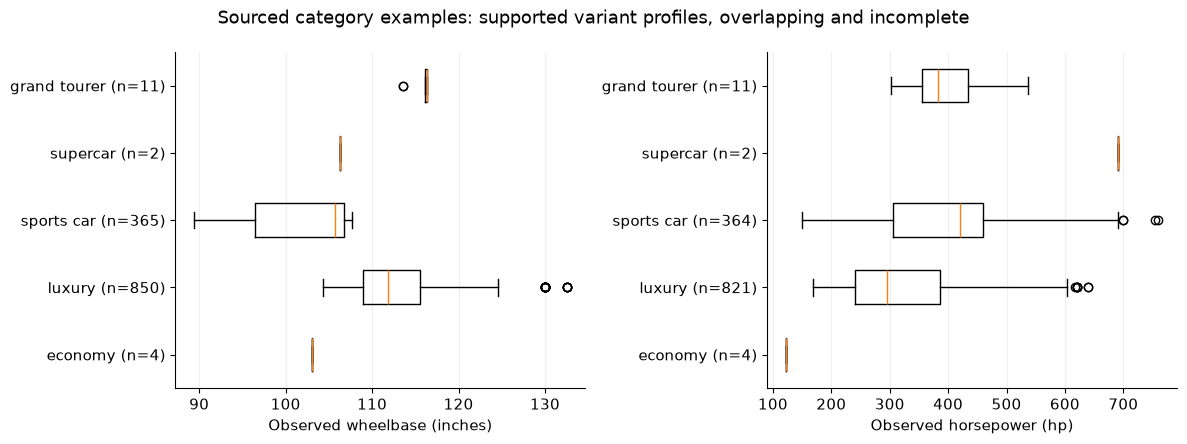

In [11]:
inventory = pd.read_csv(taxonomy_run / "coverage_inventory.csv")
display(inventory.groupby(["dimension", "reason"]).agg(identities=("Model", "size"), listings=("vin_count", "sum")))
coverage = labels.groupby(["dimension", "label"]).profile_id.nunique().rename("profiles").reset_index()
display(coverage)
display(pd.read_csv(taxonomy_run / "mapping_match_audit.csv"))
display(profiles[profiles.Make.eq("BMW") & profiles.family_resolved][["ModelYear", "Make", "Model", "Trim", "body_style", "market_family", "family_source"]].drop_duplicates().head(25))
source_receipt = taxonomy_run / "reference_results.json"
if source_receipt.is_file():
    sources = research.read_json(source_receipt)
    display(pd.Series([x["status"] for x in sources]).value_counts().rename("references"))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, field, unit in zip(axes, ["wheelbase", "horsepower"], ["inches", "hp"]):
    values, names = [], []
    for label in ["economy", "luxury", "sports_car", "supercar", "grand_tourer"]:
        ids = labels.loc[labels.label.eq(label), "profile_id"]
        observed = profiles.loc[profiles.profile_id.isin(ids), field].dropna()
        if len(observed):
            values.append(observed)
            names.append(f"{label.replace('_', ' ')} (n={len(observed)})")
    if values:
        ax.boxplot(values, vert=False, tick_labels=names)
    ax.set_xlabel(f"Observed {field.replace('_', ' ')} ({unit})")
    ax.grid(axis="x", alpha=.2)
fig.suptitle("Sourced category examples: supported variant profiles, overlapping and incomplete")
fig.tight_layout()
plt.show()


## Cohort lookup

Edit the four decoded keys below. Variant profiles retain observed VIN support and explicit unknown/conflicting residuals.

In [12]:
selected_cohort = (2013, "TOYOTA", "RAV4", "HIGH")
selected, evidence, similar = taxonomy_v2.lookup_profiles(taxonomy_run, *selected_cohort)
display(selected[[*taxonomy.KEYS, "profile_id", "vin_count", "body_style", "powertrain", "eligible", "market_family", "market_positioning_labels", "performance_character_labels"]])
display(evidence)
if len(similar):
    display(similar[["approach", "evidence_scope", "rank", *taxonomy.KEYS, "body_style", "powertrain", "distance", "year_window", "slate_size", "shared_size", "shared_powertrain"]].head(35))
else:
    print("No supported alternative-family peers under the saved compatibility and support rules.")
examples = profiles[(profiles.Model.eq("RAV4") & profiles.Trim.eq("HIGH")) | (profiles.Model.eq("SPARK") & profiles.Trim.isin(["1LT", "2LT"])) | profiles.powertrain.eq("battery_electric") | profiles.performance_character_labels.str.contains("sports_car") | (profiles.body_family.eq("pickup") & profiles.Make.eq("CADILLAC"))]
display(examples.sort_values(["ModelYear", "Make", "Model"]).groupby(["Model", "powertrain"], group_keys=False).head(1)[[*taxonomy.KEYS, "vin_count", "body_style", "powertrain", "horsepower", "engine_displacement", "eligible"]].head(30))

,ModelYear,Make,Model,Trim,profile_id,vin_count,body_style,powertrain,eligible,market_family,market_positioning_labels,performance_character_labels
11793,2013,TOYOTA,RAV4,HIGH,6d921ff0e12efe25e2164a4f,3,suv_crossover,battery_electric,False,RAV4,,
11794,2013,TOYOTA,RAV4,HIGH,65965c6ef6088fb4dc2c23d8,212,suv_crossover,unknown,True,RAV4,,


,profile_id,dimension,label,mapping_id,source_url,evidence,scope,status,taxonomy_version,namespace,definition
11457,6d921ff0e12efe25e2164a4f,body_style,suv_crossover,vin_observed_body_style,snapshot://vin_profile_membership.parquet,3 VINs in observed body_style partition,Observed subordinate profile only; parent stat...,source_supported,2.0.0,observed,Suv crossover body style supported by observed...
11458,65965c6ef6088fb4dc2c23d8,body_style,suv_crossover,vin_observed_body_style,snapshot://vin_profile_membership.parquet,212 VINs in observed body_style partition,Observed subordinate profile only; parent stat...,source_supported,2.0.0,observed,Suv crossover body style supported by observed...
19392,6d921ff0e12efe25e2164a4f,powertrain,battery_electric,vin_observed_powertrain,snapshot://vin_profile_membership.parquet,3 VINs in observed powertrain partition,Observed subordinate profile only; parent stat...,source_supported,2.0.0,observed,Supported decoded electrification and fuel evi...


,approach,evidence_scope,rank,ModelYear,Make,Model,Trim,body_style,powertrain,distance,year_window,slate_size,shared_size,shared_powertrain
0,body_year_baseline,exploratory_unknown_powertrain,1,2013,ACURA,MDX,ADVANCE,suv_crossover,unknown,0.058163,5,5,5,3
1,body_year_baseline,exploratory_unknown_powertrain,2,2013,ACURA,RDX,TECHNOLOGY PACKAGE,suv_crossover,unknown,0.027770,5,5,5,3
2,body_year_baseline,exploratory_unknown_powertrain,3,2013,AUDI,Q5,PREMIUM HYBRID,suv_crossover,unknown,0.023552,5,5,5,3
3,body_year_baseline,exploratory_unknown_powertrain,4,2013,AUDI,Q7,PREMIUM PLUS,suv_crossover,unknown,0.073462,5,5,5,2
4,body_year_baseline,exploratory_unknown_powertrain,5,2013,BMW,X1,SDRIVE28I,suv_crossover,unknown,0.040311,5,5,5,3
5,direct_specs,exploratory_unknown_powertrain,1,2008,KIA,SPORTAGE,KM,suv_crossover,unknown,0.004415,5,5,5,3
6,direct_specs,exploratory_unknown_powertrain,2,2012,HYUNDAI,SANTA FE,GL(MIDDLE-LOW ),suv_crossover,unknown,0.005110,5,5,5,3
7,direct_specs,exploratory_unknown_powertrain,3,2016,FORD,ESCAPE,SE,suv_crossover,unknown,0.005656,5,5,5,2
8,direct_specs,exploratory_unknown_powertrain,4,2009,HYUNDAI,TUCSON,JM,suv_crossover,unknown,0.005657,5,5,5,2
9,direct_specs,exploratory_unknown_powertrain,5,2012,SUZUKI,GRAND VITARA,L4 LIMITED (US)/2.4L JLX-L (CANADA),suv_crossover,unknown,0.007657,5,5,5,3


,ModelYear,Make,Model,Trim,vin_count,body_style,powertrain,horsepower,engine_displacement,eligible
245,1984,FORD,MUSTANG,GLX,3,convertible,unknown,NaN,NaN,False
328,1985,PORSCHE,911,CARRERA,2,convertible,unknown,NaN,NaN,False
698,1990,CHEVROLET,CORVETTE,ZR1,8,coupe,unknown,380.0,5700.0,True
1943,1998,FERRARI,F355,F355/F355 F1,5,conflicting,unknown,NaN,NaN,False
3273,2002,CADILLAC,ESCALADE,EXT,3,pickup,unknown,NaN,NaN,False
5978,2006,TOYOTA,RAV4,HIGH,51,suv_crossover,unknown,NaN,NaN,True
7419,2008,TESLA,ROADSTER,NaN,1,convertible,battery_electric,NaN,NaN,False
8762,2010,LAMBORGHINI,GALLARDO,SPYDER,4,convertible,unknown,NaN,NaN,False
9693,2011,MAZDA,MX-5,GRAND TOURING,11,convertible,unknown,158.0,2000.0,True
9777,2011,NISSAN,LEAF,NaN,44,hatchback,battery_electric,NaN,NaN,False


## Peer comparisons

Pairs require half the selected weight per block, two dimension fields, and one powertrain field. Known powertrains must match. Prefer five distinct families within ±5 years; record ±10 fallback. Lower specification distance alone does not establish usefulness.

In [13]:
display(pd.read_csv(taxonomy_run / "peer_diagnostics.csv"))
display(pd.read_csv(taxonomy_run / "paired_peer_comparisons.csv"))
display(pd.read_csv(taxonomy_run / "clusters/experiments.csv"))
for name in ["profiles.csv", "sensitivities.csv", "representatives.csv"]:
    path = taxonomy_run / "clusters" / name
    try:
        frame = pd.read_csv(path)
    except pd.errors.EmptyDataError:
        frame = pd.DataFrame()
    print(name)
    display(frame.head(45))
membership = pd.read_parquet(taxonomy_run / "clusters/memberships.parquet")
composition = membership.merge(labels.drop_duplicates(["profile_id", "dimension", "label"]), on="profile_id", validate="m:m")
display(composition.groupby(["experiment_id", "cluster", "dimension", "label"]).profile_id.nunique().rename("profiles").reset_index())


,approach,view,evidence_scope,query_profiles,mean_distance,complete_list_share,relaxed_share
0,body_year_baseline,global,exploratory_unknown_powertrain,66,0.119920,1.000000,0.000000
1,body_year_baseline,global,supported_powertrain,34,0.105827,1.000000,0.000000
2,category_cluster,market_positioning__luxury__passenger_car/gower,exploratory_unknown_powertrain,11,0.034312,1.000000,0.000000
3,category_cluster,market_positioning__luxury__passenger_car/gower,supported_powertrain,1,0.063707,0.000000,1.000000
4,category_cluster,market_positioning__luxury__passenger_car/kmeans,exploratory_unknown_powertrain,11,0.028058,0.818182,0.181818
5,category_cluster,market_positioning__luxury__passenger_car/kmeans,supported_powertrain,1,0.033014,0.000000,1.000000
6,category_specs,market_positioning__luxury__passenger_car,exploratory_unknown_powertrain,11,0.028038,1.000000,0.000000
7,category_specs,market_positioning__luxury__passenger_car,supported_powertrain,1,0.063707,0.000000,1.000000
8,category_specs,market_positioning__luxury__suv_crossover,exploratory_unknown_powertrain,4,0.031302,1.000000,0.000000
9,category_specs,performance_character__muscle_car__passenger_car,exploratory_unknown_powertrain,3,0.021248,0.000000,1.000000


,approach,view,paired_queries,mean_distance,direct_mean_distance,distance_change
0,body_year_baseline,global,100,0.115128,0.021139,0.093989
1,category_specs,performance_character__muscle_car__passenger_car,3,0.021248,0.023480,-0.002231
2,category_specs,performance_character__sports_car__passenger_car,9,0.083307,0.021740,0.061567
3,global_cluster,global/kmeans,100,0.025299,0.021139,0.004160
4,category_cluster,market_positioning__luxury__passenger_car/gower,12,0.036762,0.013905,0.022856
5,category_cluster,market_positioning__luxury__passenger_car/kmeans,12,0.028471,0.013905,0.014565
6,category_specs,market_positioning__luxury__passenger_car,12,0.031010,0.013905,0.017105
7,category_specs,market_positioning__luxury__suv_crossover,4,0.031302,0.011040,0.020262


,view,method,development_profiles,family_blocks,status,k,median_ari,ari_q10,silhouette,minimum_count,required_minimum_count,accepted_broad,experiment_id
0,global,kmeans,8721,456,accepted_partition,2.0,0.927250,0.788124,0.255749,3372.0,437.0,True,global/kmeans
1,global,gower,8721,456,no_supported_subdivision,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,market_positioning__economy__passenger_car,all,4,1,insufficient_support,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,market_positioning__luxury__passenger_car,kmeans,484,13,accepted_partition,2.0,0.914771,-0.072218,0.368985,90.0,25.0,True,market_positioning__luxury__passenger_car/kmeans
4,market_positioning__luxury__passenger_car,gower,484,13,accepted_partition,2.0,0.719332,-0.074360,0.406506,123.0,25.0,True,market_positioning__luxury__passenger_car/gower
5,market_positioning__luxury__suv_crossover,all,265,8,insufficient_support,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,performance_character__grand_tourer__passenger...,all,11,2,insufficient_support,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,performance_character__muscle_car__passenger_car,all,1,1,insufficient_support,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,performance_character__sports_car__passenger_car,all,247,6,insufficient_support,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,performance_character__supercar__passenger_car,all,2,1,insufficient_support,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


profiles.csv


,experiment_id,cluster,description,field,observed,missing_share,median,mode
0,global/kmeans,0,lower power,seating,7016,0.002843,5.00,NaN
1,global/kmeans,0,lower power,wheelbase,7035,0.000142,106.70,NaN
2,global/kmeans,0,lower power,height,7035,0.000142,57.70,NaN
3,global/kmeans,0,lower power,front_legroom,6916,0.017055,42.20,NaN
4,global/kmeans,0,lower power,back_legroom,6419,0.087692,35.80,NaN
5,global/kmeans,0,lower power,horsepower,6761,0.039085,204.00,NaN
6,global/kmeans,0,lower power,fuel_type,6871,0.023451,NaN,GASOLINE
7,global/kmeans,0,lower power,transmission,4738,0.326606,NaN,A
8,global/kmeans,0,lower power,wheel_system,5841,0.169841,NaN,FWD
9,global/kmeans,1,higher power,seating,3850,0.017857,7.00,NaN


sensitivities.csv


,experiment_id,sensitivity,ari
0,global/kmeans,equal_family,0.968206
1,global/kmeans,without_transmission,0.917642
2,market_positioning__luxury__passenger_car/kmeans,equal_family,-0.050284
3,market_positioning__luxury__passenger_car/kmeans,without_transmission,0.942764
4,market_positioning__luxury__passenger_car/gower,equal_family,1.000000
5,market_positioning__luxury__passenger_car/gower,without_transmission,1.000000


representatives.csv


,experiment_id,cluster,profile_id,ModelYear,Make,Model,Trim,body_style,powertrain
0,global/kmeans,0,880266f17484937c322d48c0,2004,LEXUS,ES,300,sedan,unknown
1,global/kmeans,0,1cbafe5db5d760af10fd37d5,2005,LEXUS,ES,330,sedan,unknown
2,global/kmeans,0,8e64b63cbf6f7ed3c439c4cc,2006,LEXUS,ES,330,sedan,unknown
3,global/kmeans,1,d0f32e1891738ed70f6cb26e,2019,BUICK,ENCLAVE,PREMIUM,suv_crossover,unknown
4,global/kmeans,1,5c0667934010dcd6e2413eef,2019,BUICK,ENCLAVE,AVENIR,suv_crossover,unknown
5,global/kmeans,1,be9f7326bca562a944c88a76,2019,BUICK,ENCLAVE,ESSENCE,suv_crossover,unknown
6,market_positioning__luxury__passenger_car/kmeans,0,45b4956cb3b750d98212b91c,2015,CADILLAC,ATS,STANDARD,sedan,unknown
7,market_positioning__luxury__passenger_car/kmeans,0,8703a4f7dd8fe9f26fdf6081,2018,CADILLAC,ATS,STANDARD,sedan,unknown
8,market_positioning__luxury__passenger_car/kmeans,0,67653a08f418f1be55dab0f1,2017,CADILLAC,ATS,LUXURY,sedan,unknown
9,market_positioning__luxury__passenger_car/kmeans,1,6ebc67fc4d106acf9687804c,2013,MERCEDES-BENZ,S-CLASS,S550V 4-MATIC,sedan,unknown


,experiment_id,cluster,dimension,label,profiles
0,global/kmeans,0,body_style,convertible,639
1,global/kmeans,0,body_style,coupe,879
2,global/kmeans,0,body_style,hatchback,507
3,global/kmeans,0,body_style,minivan,5
4,global/kmeans,0,body_style,pickup,34
...,...,...,...,...,...
66,market_positioning__luxury__passenger_car/kmeans,1,body_style,wagon,1
67,market_positioning__luxury__passenger_car/kmeans,1,market_positioning,luxury,116
68,market_positioning__luxury__passenger_car/kmeans,1,powertrain,hybrid,2
69,market_positioning__luxury__passenger_car/kmeans,1,powertrain,plug_in_hybrid,2


## Validation limits

Automated checks cover reconciliation, scope, compatibility, leakage, and numerical behavior. Sparse electric evidence can prevent assignment. Historical coverage does not represent the current market.

In [14]:
display(pd.read_csv(taxonomy_run / "automated_validation.csv"))
display(pd.Series(research.read_json(taxonomy_run / "evaluation.json")).to_frame("value"))
display(pd.Series(research.read_json(taxonomy_run / "combustion_sensitivity.json")).to_frame("value"))
display(parents.groupby(["body_style_status", "powertrain_status"]).size().rename("cohorts"))


,check,violations,status
0,unique_profile_ids,0,passed
1,family_split_leakage,0,passed
2,electric_displacement_coordinates,0,passed
3,width_coordinates,0,passed
4,accepted_missing_source,0,passed
5,peer_family_leakage,0,passed
6,peer_body_mismatch,0,passed
7,peer_powertrain_mismatch,0,passed
8,conflicting_peer_powertrain,0,passed
9,peer_year_window,0,passed


,value
validation,automated_only
semantic_accuracy,not_measured
buyer_usefulness,not_measured
human_review,not_performed_by_design
query_population,held_out_market_family_blocks
query_profiles,200
eligible_queries,100
reduced_budget,False


,value
status,insufficient_support
development_profiles,0
family_blocks,0
displacement_primary,False


body_style_status      powertrain_status    
assigned               assigned                   561
                       insufficient_evidence    11804
                       mixed                       13
conflicting            assigned                    68
                       conflicting                  1
                       insufficient_evidence      718
insufficient_evidence  assigned                     3
                       insufficient_evidence       34
mixed                  assigned                     1
                       insufficient_evidence     1055
Name: cohorts, dtype: int64

# Preserved specification and complaint baseline

These experiments remain separate from taxonomy labels.

## Methods

Vehicle cohorts retain separate `ModelYear`, `Make`, `Model`, `Trim`; complaints use year/make/model families. Transforms fit development Make/Model blocks and refit inside relationship-validation folds.

Complaints use complete five-year filing windows through 2026-09-30. Overlapping shares describe reporting composition, not failure rates or trim outcomes. Historical listing dates remain unverified.

Pin `VEHICLE_PROFILE_RUN_DIR`; only `VEHICLE_PROFILE_REFIT=1` enables a fresh fit.

In [15]:
from pathlib import Path
import os
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image, FileLink
root = Path.cwd()
if not (root / "MODELS").is_dir():
    root = root.parent
sys.path.insert(0, str(root))
from MODELS import vehicle_profiles as research
from MODELS import vehicle_segmentation as segmentation
saved = os.environ.get("VEHICLE_PROFILE_RUN_DIR")
refit = os.environ.get("VEHICLE_PROFILE_REFIT") == "1"
if saved:
    run = Path(saved)
elif refit:
    run = root / "MODEL_OUTPUT/vehicle_profiles" / research.datetime.now(research.timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
else:
    candidates = []
    for manifest in (root / "MODEL_OUTPUT/vehicle_profiles").glob("*/relationships/manifest.json"):
        receipt = research.read_json(manifest)
        if receipt.get("status") == "evaluated" and not receipt.get("reduced_budget", False):
            candidates.append(manifest.parent.parent)
    if not candidates:
        raise FileNotFoundError("No complete expanded full-data run. Select VEHICLE_PROFILE_RUN_DIR or explicitly enable VEHICLE_PROFILE_REFIT=1.")
    run = sorted(candidates)[-1]
if refit:
    if (run / "prepare").exists():
        raise FileExistsError("Refitting requires a fresh run directory; existing runs are immutable.")
    smoke = os.environ.get("VEHICLE_PROFILE_SMOKE") == "1"
    config = research.Config(vehicle_cap=200, medoid_cap=100, text_cap=200, starts=2, stability_refits=2, topic_refits=2, bootstrap=20, clusters=(2,3), topics=(2,3), smoke=True) if smoke else research.Config()
    research.prepare(Path(os.environ.get("VEHICLE_PROFILE_DATA_DIR", root / "DATA/CAR_DATA_FINAL")), run, config)
    research.vehicles(run)
    research.complaints(run)
    segmentation.segments(run)
    segmentation.complaint_profiles(run)
    segmentation.relationships(run)
print("Saved research run:", run)

def checked_manifest(directory):
    receipt = research.read_json(directory / "manifest.json")
    for relative, expected in receipt.get("artifacts", {}).items():
        if research.file_hash(directory / relative) != expected:
            raise ValueError(f"Changed saved artifact: {directory / relative}")
    return receipt

statuses = []
for stage in ["prepare", "vehicles", "complaints", "segments", "complaint_profiles", "relationships"]:
    directory = run / stage
    if (directory / "manifest.json").is_file():
        receipt = checked_manifest(directory)
        statuses.append({"stage":stage, "status":receipt["status"], "reduced_budget":receipt.get("reduced_budget",False)})
    else:
        statuses.append({"stage":stage, "status":"not_available_in_selected_run"})
display(pd.DataFrame(statuses))
# Historical runs can be inspected under their recorded code hashes; they are never silently refitted.


Saved research run: E:\DataScience_Capstone_Cars\MODEL_OUTPUT\vehicle_profiles\20261022T220141-segmentation-final


,stage,status,reduced_budget
0,prepare,prepared,False
1,vehicles,accepted_partition,False
2,complaints,automated_topics,False
3,segments,evaluated,False
4,complaint_profiles,evaluated,False
5,relationships,evaluated,False


## Selected-run summary

In [16]:
summary = []
for stage in ["segments", "complaint_profiles"]:
    path = run / stage / "experiments.csv"
    if path.is_file():
        try:
            frame = pd.read_csv(path)
        except pd.errors.EmptyDataError:
            frame = pd.DataFrame()
        if not frame.empty:
            frame.insert(0, "stage", stage)
            summary.append(frame)
experiment_summary = pd.concat(summary, ignore_index=True) if summary else pd.DataFrame()
if not experiment_summary.empty:
    display(experiment_summary[[c for c in ["stage","experiment_id","assigned","unassigned","k","median_ari","silhouette","minimum_count"] if c in experiment_summary]])
market_manifest = run / "segments/market/manifest.json"
if market_manifest.is_file():
    market_status = checked_manifest(market_manifest.parent)
    display(Markdown(f"**Market experiment:** `{market_status['status']}`. Mileage units require explicit source evidence."))


,stage,experiment_id,assigned,unassigned,k,median_ari,silhouette,minimum_count
0,segments,specifications/kmeans_broad,10538,3720.0,2,0.929202,0.271748,3708
1,segments,specifications/kmeans_small,10538,3720.0,2,0.929202,0.271748,3708
2,complaint_profiles,components_topics_20,2110,NaN,2,0.933089,0.116268,838
3,complaint_profiles,components_topics_50,1448,NaN,2,0.915766,0.124190,586
4,complaint_profiles,components_topics_100,904,NaN,3,0.771611,0.152440,44


**Market experiment:** `blocked_unverified_mileage_unit`. Mileage units require explicit source evidence.

## Population and support

Lowercase-VIN linkage; numerical fields require five observed VINs. Unknown, heterogeneous, and inapplicable evidence remain distinct.

,measure,value
0,retained_listings,2792999
1,conflicting_decode_vins,0
2,unmatched_listing_vins,93
3,incomplete_cohort_vins,514097
4,complete_cohorts,14258
5,primary_size_cohorts,11043
6,heterogeneous_cohorts,6041
7,representative_unavailable_cohorts,548


state,heterogeneous,not_applicable,observed,unknown
field,,,,
back_legroom_state,50,0,12421,1787
bed_length_state,53,0,612,13593
engine_displacement_state,522,68,13175,493
front_legroom_state,0,0,13262,996
height_state,0,0,13558,700
horsepower_state,553,0,13144,561
length_state,1,0,13557,700
seating_state,175,0,13383,700
wheelbase_state,2,0,13557,699


,field,development_coverage,reason,unit,block,applicable_cohorts,observed_cohorts,heterogeneous_cohorts,median_observed_vins,median_observed_agreement,listing_vpic_comparison
0,seating,0.940388,selected,seats,size,8874,8345,140,20.0,NaN,not_checked_no_shared_verified_measure
1,wheelbase,0.955601,selected,in,size,8874,8480,2,20.0,NaN,not_checked_no_shared_verified_measure
2,length,0.955713,redundant_with_wheelbase,in,size,8874,8481,1,20.0,NaN,not_checked_no_shared_verified_measure
3,height,0.955826,selected,in,size,8874,8482,0,20.0,NaN,not_checked_no_shared_verified_measure
4,horsepower,0.915371,selected,hp,powertrain,8874,8123,423,20.0,NaN,paired_ratio_audit
5,engine_displacement,0.926384,selected,cc,powertrain,8816,8167,379,20.0,NaN,paired_ratio_audit
6,width,0.955488,selected,in,size,8874,8479,3,20.0,NaN,not_checked_no_shared_verified_measure
7,front_legroom,0.936782,selected,in,size,8874,8313,0,19.0,NaN,not_checked_no_shared_verified_measure
8,back_legroom,0.883254,selected,in,size,8874,7838,45,17.0,NaN,not_checked_no_shared_verified_measure
9,fuel_type,0.911990,selected,category,powertrain,8874,8093,0,21.0,1.0,not_checked_no_shared_verified_measure


{'listing_vpic_checks': {'horsepower': {'paired_vins': 1075990,
   'median_source_reference_ratio': 1.0,
   'paired_ratio_outside_20_percent_share': 0.062230132250299726,
   'reference': 'EngineHP',
   'verified': True,
   'population': 'development VINs'},
  'engine_displacement': {'paired_vins': 1743277,
   'median_source_reference_ratio': 1.0,
   'paired_ratio_outside_20_percent_share': 0.028080448488679653,
   'reference': 'DisplacementCC',
   'verified': True,
   'population': 'development VINs'}},
 'disagreement_interpretation': 'paired median ratios check scale, not per-VIN agreement',
 'structural_missingness': 'electric fuel type marks displacement not applicable; unknown remains unknown',
 'bed_length': 'truck context only',
 'mileage_unit': 'unverified unless source manifest declares mileage unit',
 'numeric_support': 'at least five observed VIN values per modeled cohort field',
 'kmeans_missingness': 'median imputation is a modeling coordinate, never observed equipment evid

,price_n,price_median,price_q25,price_q75,mileage_n,mileage_median,mileage_q25,mileage_q75
count,14258.00,14258.00,14258.00,14258.00,14258.00,14258.00,14258.00,14258.00
mean,159.83,25683.63,24096.42,27404.48,159.83,73781.67,61426.30,87196.96
std,601.24,38887.21,37880.39,40323.06,601.24,55013.92,49342.30,61589.31
min,1.00,300.00,300.00,300.00,1.00,0.00,0.00,0.00
25%,5.00,7995.00,6998.00,8995.00,5.00,26438.62,18810.81,34495.50
50%,23.00,16500.00,14998.00,17991.00,23.00,72860.50,57161.50,87900.38
75%,90.00,30998.75,29469.12,33260.69,90.00,115000.00,96800.75,134307.88
max,14782.00,1425000.00,1425000.00,1425000.00,14782.00,331384.00,331384.00,331384.00


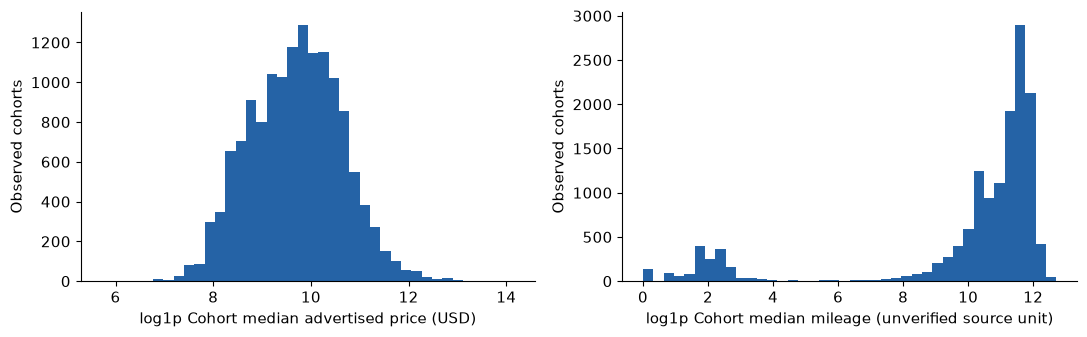

In [17]:
preparation = checked_manifest(run / "prepare")
cohorts = pd.read_parquet(run / "prepare/cohorts.parquet")
display(pd.DataFrame([{"measure": key, "value": value} for key,value in preparation.get("vehicles",{}).items() if not isinstance(value,dict)]))
state_fields = [f for f in cohorts if f.endswith("_state")]
if state_fields:
    states = cohorts[state_fields].melt(var_name="field",value_name="state")
    display(pd.crosstab(states.field,states.state))
audit_path = run / "segments/field_audit.csv"
if audit_path.is_file():
    display(pd.read_csv(audit_path))
    display(research.read_json(run / "segments/source_field_checks.json"))
support_columns = [c for c in ["price_n","price_median","price_q25","price_q75","mileage_n","mileage_median","mileage_q25","mileage_q75"] if c in cohorts]
if support_columns:
    display(cohorts[support_columns].describe().round(2))
    fig, axes = plt.subplots(1,2,figsize=(11,3.5))
    for axis, field, label in zip(axes,["price_median","mileage_median"],["Cohort median advertised price (USD)","Cohort median mileage (unverified source unit)"]):
        values = cohorts[field].dropna()
        axis.hist(np.log1p(values),bins=40,color="#2563a6")
        axis.set(xlabel="log1p " + label, ylabel="Observed cohorts")
    fig.tight_layout()
    plt.show()

## Specification segments

Thirty fixed-field family refits require ARI ≥0.70, positive silhouette, and policy support floors. Within-method selection favors smaller k within 0.02 silhouette; geometries cannot rank methods.

,method,k,median_ari,ari_q10,ari_q90,silhouette,minimum_count,development_cohorts,accepted_broad,accepted_small
0,kmeans,2,0.929202,0.856924,0.961139,0.271748,3708,8453,True,True
1,kmeans,3,0.783360,0.513042,0.926131,0.280105,830,8453,True,True
2,kmeans,4,0.843748,0.747004,0.920954,0.240829,771,8453,True,True
3,kmeans,5,0.541638,0.479542,0.859450,0.185370,613,8453,False,False
4,kmeans,6,0.577780,0.447752,0.798792,0.170586,637,8453,False,False
5,kmeans,7,0.546316,0.393276,0.820649,0.178256,44,8453,False,False
6,kmeans,8,0.503164,0.369169,0.664217,0.172594,44,8453,False,False
7,gower,2,0.688517,0.207025,0.894727,0.282586,2967,8453,False,False
8,gower,3,0.433579,0.206373,0.600130,0.208393,872,8453,False,False
9,gower,4,0.389159,0.233377,0.509221,0.093413,1430,8453,False,False


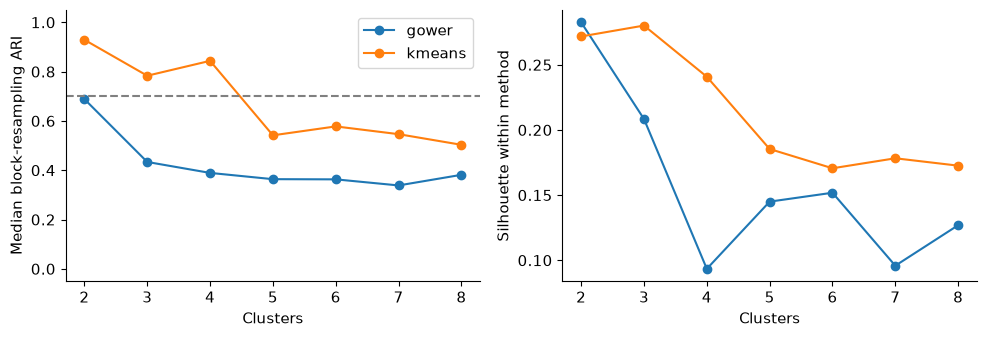

In [18]:
comparison = run / "segments/specifications/model_comparison.csv"
if comparison.is_file():
    scores = pd.read_csv(comparison)
    display(scores)
    fig, axes = plt.subplots(1,2,figsize=(10,3.5))
    for method,group in scores.groupby("method"):
        axes[0].plot(group.k,group.median_ari,marker="o",label=method)
        axes[1].plot(group.k,group.silhouette,marker="o",label=method)
    axes[0].axhline(.7,color="gray",linestyle="--")
    axes[0].set(xlabel="Clusters",ylabel="Median block-resampling ARI",ylim=(-.05,1.05))
    axes[1].set(xlabel="Clusters",ylabel="Silhouette within method")
    axes[0].legend()
    fig.tight_layout()
    plt.show()
else:
    print("No expanded specification experiment; inspect the saved stage status.")

### Membership and missingness

PCA is display-only. Examples are observed cohorts, not guaranteed substitutes. Complete-case comparisons change populations; legacy/expanded comparisons also change policies and are not single-field ablations. Box plots omit outlier marks.

kmeans_broad


,cluster,assignment_status,cohorts
0,-1,insufficient_evidence,3720
1,0,assigned,4458
2,1,assigned,6080


,sensitivity,common_cohorts,development_complete,development_total,ari,fields_frozen,mean_absolute_distance_change
0,complete_case_overlap,635,5574.0,8453.0,0.889654,True,NaN
1,same_anchor_population_refit,1000,5574.0,8453.0,0.890979,True,NaN
2,observed_pair_vs_imputed_gower,1000,NaN,NaN,NaN,True,0.014044
3,equal_family_fitting,1000,NaN,NaN,0.910019,True,NaN


,reference,ari
0,body,0.046092
1,body_powertrain,0.016393


E:\DataScience_Capstone_Cars\MODEL_OUTPUT\vehicle_profiles\20261022T220141-segmentation-final\segments\specifications\kmeans_broad\cluster_cohorts.html

,common_assigned_cohorts,partition_ari,legacy_only_assigned,expanded_only_assigned
0,10233,0.52305,112,305


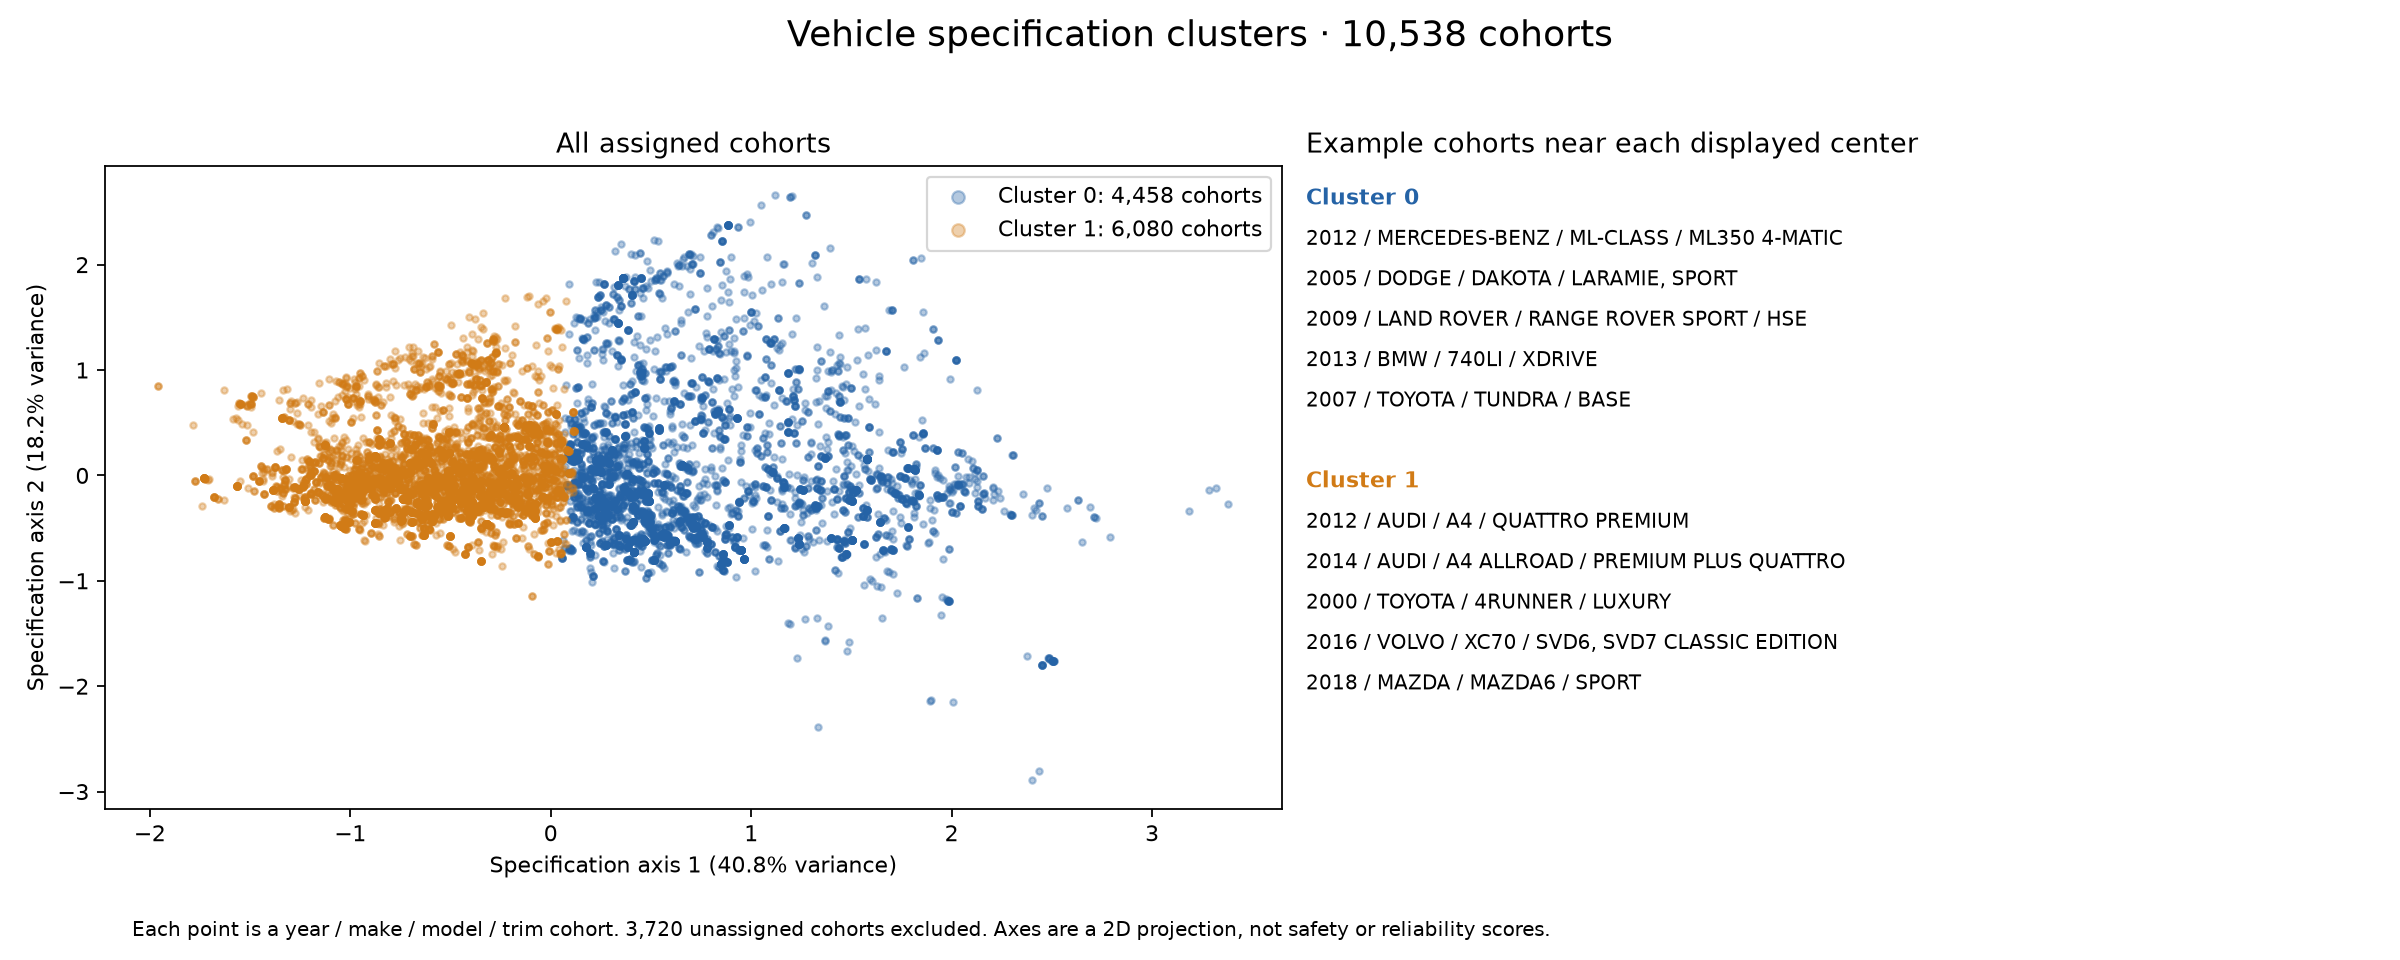

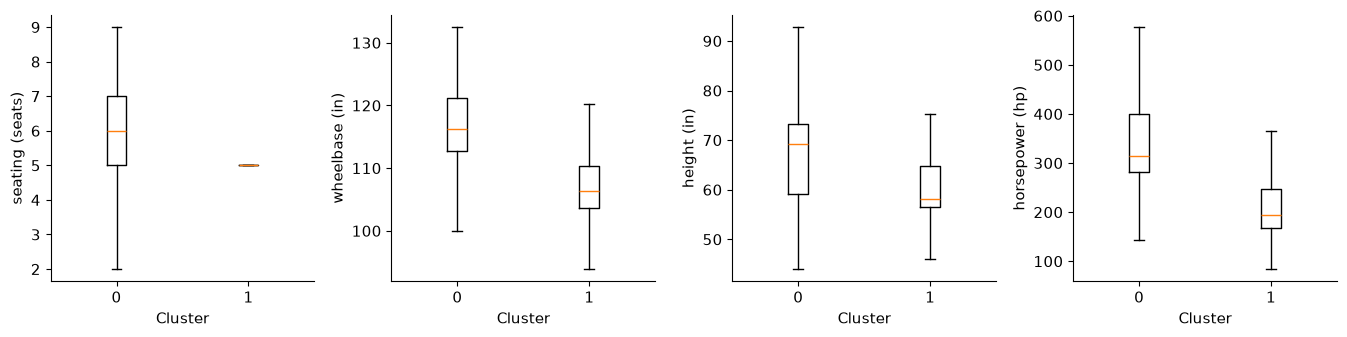

,ModelYear,Make,Model,Trim,cluster,experiment_id,vin,seating,wheelbase,length,height,horsepower,engine_displacement,fuel_type,wheel_system,transmission,representative_status,numeric_fields_observed
4,1981,FIAT,SPIDER 2000,BASIC,1,specifications/kmeans_broad,ZFAAS00B2B8185325,2.0,89.8,162.9,50.0,102.0,2000.0,GASOLINE,RWD,A,numeric_match,6
12,1981,MERCEDES-BENZ,380,SL,1,specifications/kmeans_broad,WDBBA45A9BB003418,2.0,96.9,182.0,50.0,155.0,3800.0,GASOLINE,RWD,NaN,numeric_match,6
217,1989,JEEP,GRAND WAGONEER,BASE,0,specifications/kmeans_broad,1J4GS5879KP111691,6.0,108.7,186.0,66.0,144.0,5900.0,GASOLINE,4WD,A,numeric_match,6
464,1994,DODGE,VIPER,RT/10,0,specifications/kmeans_broad,1B3BR65EXRV102185,2.0,96.2,175.1,44.0,400.0,8000.0,GASOLINE,RWD,M,numeric_match,6


kmeans_small: identical frozen partition to the broad policy; detailed results are shown once.


E:\DataScience_Capstone_Cars\MODEL_OUTPUT\vehicle_profiles\20261022T220141-segmentation-final\segments\specifications\kmeans_small\manifest.json

In [19]:
segment_paths = sorted((run / "segments/specifications").glob("*/membership.parquet"))
for path in segment_paths:
    directory = path.parent
    if directory.name.endswith("_small"):
        broad = directory.parent / directory.name.replace("_small","_broad")
        if (broad / "partition.joblib").is_file() and research.file_hash(broad / "partition.joblib") == research.file_hash(directory / "partition.joblib"):
            checked_manifest(directory)
            print(directory.name + ": identical frozen partition to the broad policy; detailed results are shown once.")
            display(FileLink(os.path.relpath(directory / "manifest.json",Path.cwd()),result_html_prefix="Policy artifact receipt: "))
            continue
    print(directory.name)
    checked_manifest(directory)
    membership = pd.read_parquet(path)
    display(membership.groupby(["cluster","assignment_status"]).size().rename("cohorts").reset_index())
    display(pd.read_csv(directory / "sensitivities.csv"))
    display(pd.read_csv(directory / "reference_agreement.csv"))
    display(FileLink(os.path.relpath(directory / "cluster_cohorts.html",Path.cwd()),result_html_prefix="Interactive cohort chart: "))
    if directory.name == "kmeans_broad":
        baseline_path = run / "vehicles/assignments.parquet"
        if baseline_path.is_file():
            legacy = pd.read_parquet(baseline_path,columns=research.COHORT+["cluster"])
            paired = legacy.merge(membership[research.COHORT+["cluster"]],on=research.COHORT,validate="one_to_one",suffixes=("_legacy","_expanded"))
            common = (paired.cluster_legacy>=0)&(paired.cluster_expanded>=0)
            display(pd.DataFrame([{"common_assigned_cohorts":int(common.sum()),"partition_ari":research.adjusted_rand_score(paired.loc[common,"cluster_legacy"],paired.loc[common,"cluster_expanded"]),"legacy_only_assigned":int(((paired.cluster_legacy>=0)&(paired.cluster_expanded<0)).sum()),"expanded_only_assigned":int(((paired.cluster_legacy<0)&(paired.cluster_expanded>=0)).sum())}]))
        display(Image(filename=str(directory / "cluster_cohorts.png")))
        observed = membership[membership.cluster >= 0]
        fields = [f for f in ["seating","wheelbase","height","horsepower"] if observed[f].notna().any()]
        fig,axes = plt.subplots(1,len(fields),figsize=(3.4*len(fields),3.5),squeeze=False)
        for axis,field in zip(axes[0],fields):
            groups = [(cluster,group[field].dropna()) for cluster,group in observed.groupby("cluster")]
            axis.boxplot([values for _,values in groups],tick_labels=[str(cluster) for cluster,_ in groups],showfliers=False)
            axis.set(xlabel="Cluster",ylabel=field + " (" + research.UNITS[field] + ")")
        fig.tight_layout()
        plt.show()
        representatives = pd.read_parquet(directory / "representative_vehicles.parquet")
        display(representatives[representatives.cluster >= 0].groupby("cluster").head(2))

## Market-aware segments

Log median price and log1p median mileage receive one-third block weight. Fitting requires verified mileage units and support. Historical inventory composition is not current affordability or depreciation.

In [20]:
market = run / "segments/market"
if (market / "manifest.json").is_file():
    display(checked_manifest(market))
    for path in sorted(market.glob("*/membership.parquet")):
        display(pd.read_csv(path.parent / "profiles.csv",header=[0,1],index_col=0))
agreement = run / "segments/representation_agreement.csv"
if agreement.is_file():
    display(pd.read_csv(agreement))

{'stage': 'market',
 'status': 'blocked_unverified_mileage_unit',
 'artifacts': {},
 'completed_at': '2026-10-22T22:16:05.850021+00:00',
 'code_sha256': '1231bd35e69886cbd119c9be36e17362ef1043ca96022cb23010dd8662cc538c',
 'elapsed_seconds': 0.0011614998802542686,
 'segmentation_code_sha256': '526f5ba83f072760488d086ecb199622564e56b4379efeb79f0ce34062f9c8f7',
 'evidence': {'verified': False,
  'unit': None,
  'evidence': 'E:\\DataScience_Capstone_Cars\\DATA\\CAR_DATA_FINAL\\manifest.json',
  'source_manifest_sha256': 'd582ae7267be2bfc7a63c06808bb09de6b5fd367d74efd67440eac76a2e77fab',
  'reason': 'source unit metadata absent'}}

,experiment,common_cohorts,common_development_cohorts,full_fit_common_member_ari,common_population_refit_ari


## Complaint profiles

Overlapping incident shares need not sum to one. Support thresholds are 20/50/100 incidents; component-plus-topic fits are separate sensitivities. Topic semantics remain unvalidated; iteration-limit warnings limit refit interpretation.

{'distinct_incidents': 332876,
 'unmapped_incidents': 73864,
 'overlapping_category_incidents': 35026,
 'patterns': {'powertrain': 'ENGINE|POWER TRAIN',
  'brakes': 'BRAKE',
  'steering': 'STEERING',
  'electrical': 'ELECTRICAL',
  'airbags': 'AIR BAG',
  'fuel': 'FUEL SYSTEM',
  'structure': 'STRUCTURE',
  'visibility': 'VISIBILITY|EXTERIOR LIGHTING'},
 'shares_sum_to_one': False}

,components,records,matched_categories
1610,POWER TRAIN,32067,1
160,ELECTRICAL SYSTEM,24271,1
2760,STEERING,19434,1
0,AIR BAGS,17031,1
2159,"SERVICE BRAKES, HYDRAULIC",15909,1
589,ENGINE AND ENGINE COOLING,15368,1
4417,UNKNOWN OR OTHER,15080,0
588,ENGINE,14941,1
3670,STRUCTURE,11408,1
4471,VEHICLE SPEED CONTROL,10813,0


,components,records,matched_categories
4417,UNKNOWN OR OTHER,15080,0
4471,VEHICLE SPEED CONTROL,10813,0
3765,SUSPENSION,10544,0
4373,TIRES,8782,0
1477,FUEL/PROPULSION SYSTEM,4831,0
1993,SEAT BELTS,4194,0
2056,SEATS,3816,0
4665,WHEELS,3405,0
1509,LATCHES/LOCKS/LINKAGES,2886,0
1048,EQUIPMENT,1836,0


,experiment,status,minimum_complaints,selected_k
0,components_100,no_supported_partition,100,NaN
1,components_20,no_supported_partition,20,NaN
2,components_50,no_supported_partition,50,NaN
3,components_topics_100,accepted_partition,100,3.0
4,components_topics_20,accepted_partition,20,2.0
5,components_topics_50,accepted_partition,50,2.0


,topic_count,iterations,iteration_limit,at_iteration_limit
0,10,73,400,False
1,20,93,400,False
2,30,127,400,False


No accepted primary complaint partition; continuous family profiles remain available.


,method,k,median_ari,ari_q10,ari_q90,silhouette,minimum_count,development_cohorts,accepted_broad,accepted_small
0,kmeans,2,0.611149,0.173977,0.754225,0.122459,821,1730,False,False
1,kmeans,3,0.455991,0.365293,0.654880,0.131028,86,1730,False,False
2,kmeans,4,0.405255,0.298287,0.552557,0.152801,85,1730,False,False
3,kmeans,5,0.407573,0.321210,0.548497,0.162181,80,1730,False,False
4,kmeans,6,0.544955,0.457495,0.660350,0.166961,61,1730,False,False
5,kmeans,7,0.542444,0.363621,0.594631,0.195564,57,1730,False,False
6,kmeans,8,0.765107,0.461314,0.884682,0.212243,47,1730,False,False


,cluster,families
0,0,1077
1,1,1033


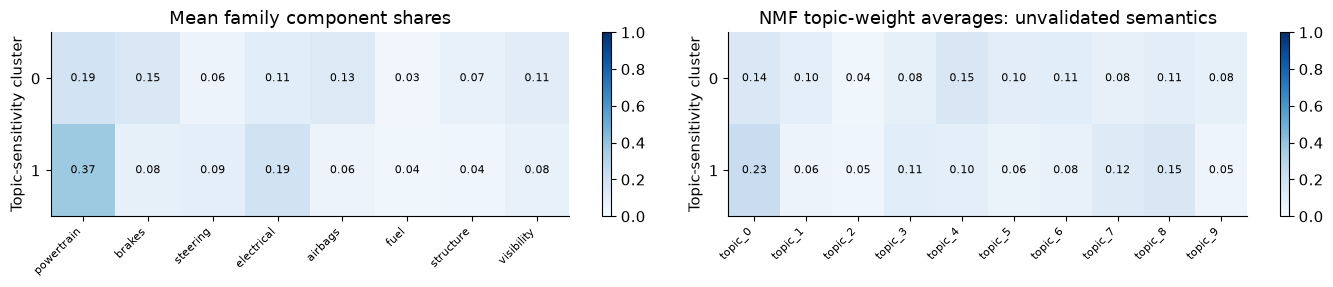

In [21]:
complaint_root = run / "complaint_profiles"
if (complaint_root / "taxonomy_audit.json").is_file():
    display(research.read_json(complaint_root / "taxonomy_audit.json"))
    mapping = pd.read_csv(complaint_root / "component_mapping_receipt.csv")
    display(mapping.sort_values("records",ascending=False).head(12))
    display(mapping[mapping.matched_categories == 0].sort_values("records",ascending=False).head(10))
    profile_statuses = []
    for manifest in sorted(complaint_root.glob("*/manifest.json")):
        receipt = checked_manifest(manifest.parent)
        profile_statuses.append({"experiment":manifest.parent.name,"status":receipt["status"],"minimum_complaints":receipt.get("minimum_complaints"),"selected_k":receipt.get("selected",{}).get("k")})
    display(pd.DataFrame(profile_statuses))
topic_models = run / "complaints/topics.joblib"
if topic_models.is_file():
    saved_topics = research.joblib.load(topic_models)
    display(pd.DataFrame([{"topic_count": count, "iterations": model.n_iter_, "iteration_limit": model.max_iter, "at_iteration_limit": model.n_iter_ >= model.max_iter} for count,model in saved_topics["models"].items()]))
primary = complaint_root / "components_20"
if (primary / "membership.parquet").is_file():
    membership = pd.read_parquet(primary / "membership.parquet")
    display(membership.groupby(["cluster","assignment_status"]).size().rename("families").reset_index())
    fields = [f for f in membership if f.startswith("component_")]
    matrix = membership[membership.cluster >= 0].groupby("cluster")[fields].mean()
    display(matrix.round(3))
    fig,axis = plt.subplots(figsize=(11,max(3,len(matrix)*.65)))
    image = axis.imshow(matrix.to_numpy(),aspect="auto",vmin=0,vmax=1,cmap="Blues")
    axis.set(xticks=range(len(fields)),xticklabels=[f.removeprefix("component_") for f in fields],yticks=range(len(matrix)),yticklabels=matrix.index,xlabel="Component category",ylabel="Complaint cluster")
    plt.setp(axis.get_xticklabels(),rotation=35,ha="right")
    fig.colorbar(image,ax=axis,label="Mean family complaint share")
    fig.tight_layout()
    plt.show()
else:
    print("No accepted primary complaint partition; continuous family profiles remain available.")
    comparison_path = primary / "model_comparison.csv"
    if comparison_path.is_file():
        display(pd.read_csv(comparison_path))
secondary = complaint_root / "components_topics_20"
if (secondary / "membership.parquet").is_file():
    topic_membership = pd.read_parquet(secondary / "membership.parquet")
    assigned_topics = topic_membership[topic_membership.cluster >= 0]
    display(assigned_topics.groupby("cluster").size().rename("families").reset_index())
    components = [f for f in assigned_topics if f.startswith("component_")]
    topics = [f for f in assigned_topics if f.startswith("topic_") and f != "topic_complaint_count"]
    fig,axes = plt.subplots(1,2,figsize=(14,max(3,assigned_topics.cluster.nunique()*.65)))
    for axis,fields,title in zip(axes,[components,topics],["Mean family component shares","NMF topic-weight averages: unvalidated semantics"]):
        matrix = assigned_topics.groupby("cluster")[fields].mean()
        image = axis.imshow(matrix.to_numpy(),aspect="auto",vmin=0,vmax=1,cmap="Blues")
        for row in range(len(matrix)):
            for column in range(len(fields)):
                axis.text(column,row,f"{matrix.iat[row,column]:.2f}",ha="center",va="center",fontsize=8,color="white" if matrix.iat[row,column]>.5 else "black")
        axis.set(xticks=range(len(fields)),xticklabels=[f.removeprefix("component_") for f in fields],yticks=range(len(matrix)),yticklabels=matrix.index,title=title,ylabel="Topic-sensitivity cluster")
        plt.setp(axis.get_xticklabels(),rotation=45,ha="right",fontsize=8)
        fig.colorbar(image,ax=axis)
    fig.tight_layout()
    plt.show()


### Assignment uncertainty

Two hundred incident-bootstrap draws flag modal support <80%. Disjoint halves check families with ≥50 incidents. Neither measures reporting bias or failure risk.

No accepted primary component partition; assignment uncertainty is unavailable.


,modal_assignment_support,uncertain
count,2110.000000,2110
unique,NaN,2
top,NaN,False
freq,NaN,1767
mean,0.922526,NaN
std,0.127454,NaN
min,0.500000,NaN
25%,0.886250,NaN
50%,1.000000,NaN
75%,1.000000,NaN


,families,half_assignment_agreement
0,1460,0.889726


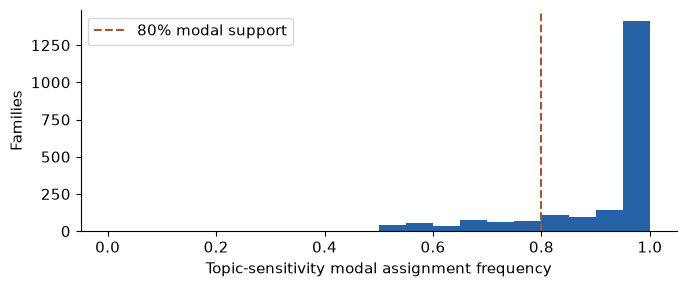

,minimum_incidents,common_assigned_families,assignment_ari
0,50,1448,0.889871
1,100,904,0.717271


In [22]:
uncertainty_path = primary / "assignment_uncertainty.csv"
if uncertainty_path.is_file():
    uncertainty = pd.read_csv(uncertainty_path)
    family_support = uncertainty.drop_duplicates(research.FAMILY)
    display(family_support[["modal_assignment_support","uncertain"]].describe(include="all"))
    halves = pd.read_csv(primary / "independent_halves.csv")
    display(pd.DataFrame([{"families":len(halves),"half_assignment_agreement":halves.agreement.mean() if len(halves) else None}]))
    fig,axis = plt.subplots(figsize=(7,3))
    axis.hist(family_support.modal_assignment_support,bins=np.linspace(0,1,21),color="#2563a6")
    axis.axvline(.8,color="#a45632",linestyle="--",label="80% modal support")
    axis.set(xlabel="Modal bootstrap assignment frequency",ylabel="Families")
    axis.legend()
    fig.tight_layout()
    plt.show()
else:
    print("No accepted primary component partition; assignment uncertainty is unavailable.")
if (secondary / "assignment_uncertainty.csv").is_file():
    uncertainty = pd.read_csv(secondary / "assignment_uncertainty.csv")
    family_support = uncertainty.drop_duplicates(research.FAMILY)
    display(family_support[["modal_assignment_support","uncertain"]].describe(include="all"))
    halves = pd.read_csv(secondary / "independent_halves.csv")
    display(pd.DataFrame([{"families":len(halves),"half_assignment_agreement":halves.agreement.mean() if len(halves) else None}]))
    fig,axis=plt.subplots(figsize=(7,3))
    axis.hist(family_support.modal_assignment_support,bins=np.linspace(0,1,21),color="#2563a6")
    axis.axvline(.8,color="#a45632",linestyle="--",label="80% modal support")
    axis.set(xlabel="Topic-sensitivity modal assignment frequency",ylabel="Families")
    axis.legend()
    fig.tight_layout()
    plt.show()

support_agreement = []
if (secondary / "membership.parquet").is_file():
    reference = pd.read_parquet(secondary / "membership.parquet",columns=research.FAMILY+["cluster"])
    for minimum in [50,100]:
        candidate = complaint_root / f"components_topics_{minimum}/membership.parquet"
        if candidate.is_file():
            other = pd.read_parquet(candidate,columns=research.FAMILY+["cluster"])
            paired = reference.merge(other,on=research.FAMILY,validate="one_to_one",suffixes=("_reference","_sensitivity"))
            common = (paired.cluster_reference>=0)&(paired.cluster_sensitivity>=0)
            support_agreement.append({"minimum_incidents":minimum,"common_assigned_families":int(common.sum()),"assignment_ari":research.adjusted_rand_score(paired.loc[common,"cluster_reference"],paired.loc[common,"cluster_sensitivity"]) if common.sum()>1 else None})
    display(pd.DataFrame(support_agreement))


## Relationships between representations

Family mixtures retain unassigned trims; primary coverage is ≥80%. Four Ridge arms compare baseline, clusters, continuous inputs, and both. Both-versus-continuous tests representation value, not independent evidence. Upstream fits refit within development folds.

Prior held-out use makes results exploratory. Family-block intervals are unadjusted for multiple outcomes; associations are not causal or trim-specific.

specifications_kmeans_broad


variant,baseline,both,clusters,continuous
outcome,,,,
component_airbags,7.015,7.116,7.223,7.125
component_brakes,7.473,7.481,7.454,7.469
component_electrical,8.655,8.674,8.590,8.684
component_fuel,3.216,3.291,3.282,3.265
component_powertrain,13.551,13.054,13.267,13.121
component_steering,5.431,5.259,5.395,5.273
component_structure,4.298,4.365,4.234,4.369
component_visibility,8.514,8.582,8.682,8.530


,coverage_policy,outcome,variant,reference,mean_mae_change,lower,upper,heldout_blocks,interval_status
2,primary,component_powertrain,both,continuous,-0.066445,-0.191948,0.060317,46,available
5,primary,component_brakes,both,continuous,0.011415,-0.016128,0.041909,46,available
8,primary,component_steering,both,continuous,-0.014033,-0.047608,0.023413,46,available
11,primary,component_electrical,both,continuous,-0.010105,-0.035234,0.021017,46,available
14,primary,component_airbags,both,continuous,-0.008764,-0.019097,0.001249,46,available
17,primary,component_fuel,both,continuous,0.025632,-0.006663,0.056977,46,available
20,primary,component_structure,both,continuous,-0.004647,-0.136050,0.121656,46,available
23,primary,component_visibility,both,continuous,0.052439,-0.010146,0.115437,46,available


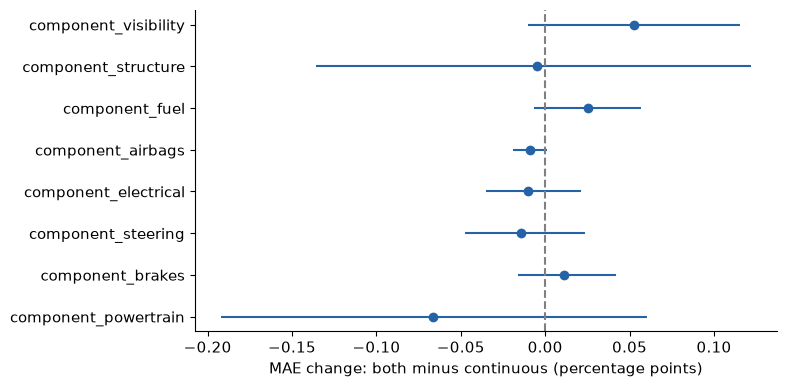

specifications_kmeans_small
Equivalent policy evaluation; this is not an independent replication.


E:\DataScience_Capstone_Cars\MODEL_OUTPUT\vehicle_profiles\20261022T220141-segmentation-final\relationships\specifications_kmeans_small\reuse_receipt.json

Vehicle/complaint-cluster cross-profiles are unavailable without an accepted primary complaint partition. The four-arm comparisons use continuous component outcomes.


In [23]:
for path in sorted((run / "relationships").glob("*/comparison.csv")):
    directory = path.parent
    print(directory.name)
    receipt = checked_manifest(directory)
    if receipt.get("execution") == "reused_verified_equivalent_evaluation":
        print("Equivalent policy evaluation; this is not an independent replication.")
        display(FileLink(os.path.relpath(directory / "reuse_receipt.json",Path.cwd()),result_html_prefix="Input/output equivalence receipt: "))
        continue
    report = pd.read_csv(path)
    evaluated = report[report.status == "evaluated"]
    if not evaluated.empty:
        display((evaluated[evaluated.coverage_policy == "primary"].pivot(index="outcome",columns="variant",values="mae")*100).round(3))
        intervals = pd.read_csv(directory / "paired_intervals.csv")
        shown = intervals[(intervals.coverage_policy == "primary") & (intervals.variant == "both")].copy()
        for field in ["mean_mae_change","lower","upper"]:
            shown[field] *= 100
        display(shown)
        available = shown.dropna(subset=["lower","upper"])
        if not available.empty:
            fig,axis = plt.subplots(figsize=(8,4))
            y=np.arange(len(available))
            axis.hlines(y,available.lower,available.upper,color="#2563a6")
            axis.scatter(available.mean_mae_change,y,color="#2563a6")
            axis.axvline(0,color="gray",linestyle="--")
            axis.set(yticks=y,yticklabels=available.outcome,xlabel="MAE change: both minus continuous (percentage points)")
            fig.tight_layout()
            plt.show()
    else:
        display(report)
    cross = directory / "complaint_vehicle_cross_profiles.csv"
    if cross.is_file():
        display(pd.read_csv(cross))
if not (primary / "membership.parquet").is_file():
    print("Vehicle/complaint-cluster cross-profiles are unavailable without an accepted primary complaint partition. The four-arm comparisons use continuous component outcomes.")

### Topic-profile associations

These use the component-plus-topic sensitivity, conditional on frozen assignments. Fewer than 20 blocks yields no interval. Saved inspection stays read-only.

In [24]:
topic_associations = run / "topic_associations"
if refit:
    target = research.begin_stage(run, "topic_associations")
    topic_path = run / "complaint_profiles/components_topics_20/membership.parquet"
    if topic_path.is_file():
        research.verified_stage(run, "complaint_profiles")
        research.verified_stage(run, "relationships")
        config = research.run_config(research.read_json(run / "prepare/manifest.json"))
        for path in sorted((run / "relationships").glob("*/family_mixtures.parquet")):
            destination = research.begin_stage(target, path.parent.name)
            segmentation.cross_profile_bootstrap(pd.read_parquet(path),pd.read_parquet(topic_path),config,destination)
            research.finish_stage(destination,"evaluated",vehicle_experiment=path.parent.name,complaint_experiment="components_topics_20",family_mixtures_sha256=research.file_hash(path),topic_membership_sha256=research.file_hash(topic_path))
        research.finish_stage(target,"evaluated",interpretation="exploratory associations with component-plus-topic sensitivity; unvalidated semantics",relationships_manifest_sha256=research.file_hash(run / "relationships/manifest.json"))
    else:
        research.finish_stage(target,"unavailable_no_accepted_topic_partition")
if (topic_associations / "manifest.json").is_file():
    display(checked_manifest(topic_associations)["status"])
    seen_tables = set()
    for path in sorted(topic_associations.glob("*/complaint_vehicle_cross_profiles.csv")):
        print(path.parent.name)
        digest = research.file_hash(path)
        if digest in seen_tables:
            print("Same saved cross-profile table as the equivalent policy; shown once.")
            display(FileLink(os.path.relpath(path,Path.cwd()),result_html_prefix="Cross-profile artifact: "))
            continue
        seen_tables.add(digest)
        display(pd.read_csv(path))
else:
    print("Supplemental topic-profile associations are not available in this saved run.")


'evaluated'

specifications_kmeans_broad


,complaint_cluster,vehicle_share,mean,lower,upper,families,make_model_blocks
0,0,cluster_0,0.221764,0.169614,0.278564,1077,244
1,0,cluster_1,0.410416,0.351806,0.465880,1077,244
2,0,unassigned_share,0.367820,0.328117,0.416839,1077,244
3,1,cluster_0,0.308747,0.245966,0.371570,1033,254
4,1,cluster_1,0.513606,0.450528,0.577724,1033,254
5,1,unassigned_share,0.177647,0.149138,0.209074,1033,254


specifications_kmeans_small
Same saved cross-profile table as the equivalent policy; shown once.


E:\DataScience_Capstone_Cars\MODEL_OUTPUT\vehicle_profiles\20261022T220141-segmentation-final\topic_associations\specifications_kmeans_small\complaint_vehicle_cross_profiles.csv

## Limits

Interpret each run under its own manifest. Unsupported partitions and unit blockers remain results; no partition establishes reliability or buyer suitability.